<a href="https://colab.research.google.com/github/sets1623/AI-SmartGrid-Forecasting/blob/main/AtmoGraph_Day01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Welcome to AtmoGraph!")
print("Supply Chain Ripple Effect Predictor")
print("Project Development Started Successfully!")

Welcome to AtmoGraph!
Supply Chain Ripple Effect Predictor
Project Development Started Successfully!


In [2]:
import pandas as pd
import numpy as np

print("AtmoGraph Environment Ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

AtmoGraph Environment Ready!
Pandas: 2.2.3
NumPy: 2.4.6


In [3]:
import os

folders = [
    "AtmoGraph",
    "AtmoGraph/raw_data",
    "AtmoGraph/processed_data",
    "AtmoGraph/models",
    "AtmoGraph/reports",
    "AtmoGraph/visualizations"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("AtmoGraph project workspace created!")

for folder in folders:
    print("Created:", folder)

AtmoGraph project workspace created!
Created: AtmoGraph
Created: AtmoGraph/raw_data
Created: AtmoGraph/processed_data
Created: AtmoGraph/models
Created: AtmoGraph/reports
Created: AtmoGraph/visualizations


In [4]:
import zipfile
import os

zip_path = "/content/8gx2fvg2k6-5.zip"
extract_path = "/content/AtmoGraph/raw_data"

# Check whether ZIP file exists
if not os.path.exists(zip_path):
    print("ERROR: ZIP file not found!")
else:
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")

    print("\nFiles available:")

    for file in os.listdir(extract_path):
        print("✓", file)

Dataset extracted successfully!

Files available:
✓ tokenized_access_logs.csv
✓ DataCoSupplyChainDataset.csv
✓ DescriptionDataCoSupplyChain.csv


In [5]:
import os

print(os.listdir("/content"))

['.config', 'AtmoGraph', '8gx2fvg2k6-5.zip', 'sample_data']


In [6]:
import zipfile
import os

zip_path = "/8gx2fvg2k6-5.zip"

extract_path = "/content/AtmoGraph/raw_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("SUCCESS! Dataset extracted.")

print("\nAvailable files:")

for file in os.listdir(extract_path):
    print(file)

FileNotFoundError: [Errno 2] No such file or directory: '/8gx2fvg2k6-5.zip'

In [ ]:
import pandas as pd
import os

# Main dataset location
file_path = "/content/AtmoGraph/raw_data/DataCoSupplyChainDataset.csv"

# Check dataset availability
if os.path.exists(file_path):

    print("Dataset found successfully!")

    # Load dataset
    df = pd.read_csv(file_path, encoding="latin1")

    print("\nDATASET LOADED SUCCESSFULLY!")
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    print("\nFirst 5 records:")
    display(df.head())

else:
    print("Dataset not found. Check extraction first.")


In [ ]:
# AtmoGraph - Dataset Column Analysis

print("TOTAL COLUMNS:", len(df.columns))

print("\nALL DATASET COLUMNS:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, "-", column)

print("\nDATA TYPES:\n")
print(df.dtypes)

In [ ]:
# AtmoGraph - Data Quality Analysis

print("DATASET QUALITY REPORT")
print("=======================")

print("\nTotal Records:", len(df))

print("\nMissing Values in Each Column:")

missing = df.isnull().sum()

display(
    missing[missing > 0]
    .sort_values(ascending=False)
)

print("\nDuplicate Records:", df.duplicated().sum())

print("\nDataset Information:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

In [ ]:
# AtmoGraph - Target Variable Analysis

target = "Late_delivery_risk"

if target in df.columns:

    print("TARGET VARIABLE FOUND!")

    print("\nLate Delivery Risk Distribution:")

    display(df[target].value_counts())

    print("\nPercentage Distribution:")

    display(
        df[target].value_counts(normalize=True) * 100
    )

else:
    print("Target variable not found.")
    print("Available columns:", df.columns.tolist())

In [ ]:
# AtmoGraph - Shipping Risk Analysis

print("SHIPPING MODE ANALYSIS")
print("=======================")

shipping_analysis = pd.crosstab(
    df["Shipping Mode"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100

display(shipping_analysis)

# Visualize the results
shipping_analysis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Late Delivery Risk by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Percentage (%)")
plt.legend(["No Risk", "Late Delivery Risk"])
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

shipping_analysis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Late Delivery Risk by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Percentage (%)")
plt.legend(["No Risk", "Late Delivery Risk"])
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# AtmoGraph - Delivery Delay Analysis

print("DELIVERY DELAY ANALYSIS")
print("========================")

# Select delivery-related columns
delivery_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status"
]

# Check whether columns exist
available_columns = [
    col for col in delivery_columns
    if col in df.columns
]

print("\nAvailable delivery columns:")
print(available_columns)

# Display delivery information
display(df[available_columns].head(10))

# Statistical analysis
numeric_columns = [
    col for col in available_columns
    if col != "Delivery Status"
]

print("\nDelivery Statistics:")
display(df[numeric_columns].describe())

In [ ]:
# AtmoGraph - Delivery Delay Calculation

df["Delay_Days"] = (
    df["Days for shipping (real)"]
    - df["Days for shipment (scheduled)"]
)

print("DELIVERY DELAY CALCULATED SUCCESSFULLY!")

print("\nFirst 10 Records:")

display(df[[
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delay_Days",
    "Delivery Status"
]].head(10))

print("\nDelay Statistics:")

display(df["Delay_Days"].describe())

print("\nLate Orders:", (df["Delay_Days"] > 0).sum())
print("On-time or Early Orders:", (df["Delay_Days"] <= 0).sum())

In [ ]:
import matplotlib.pyplot as plt

# Categorize delivery delays
delay_counts = pd.Series({
    "Early": (df["Delay_Days"] < 0).sum(),
    "On Time": (df["Delay_Days"] == 0).sum(),
    "Delayed": (df["Delay_Days"] > 0).sum()
})

print("DELIVERY PERFORMANCE")
display(delay_counts.to_frame("Number of Orders"))

# Create visualization
plt.figure(figsize=(8, 5))
delay_counts.plot(kind="bar")

plt.title("AtmoGraph - Delivery Performance Analysis")
plt.xlabel("Delivery Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Analyze late-delivery risk by order type

order_analysis = pd.crosstab(
    df["Type"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100

print("LATE DELIVERY RISK BY ORDER TYPE")

display(order_analysis.round(2))

# Visualize the results
order_analysis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Late Delivery Risk by Order Type")
plt.xlabel("Order Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 20: Select machine learning features

target = "Late_delivery_risk"

candidate_features = [
    "Type",
    "Shipping Mode",
    "Market",
    "Customer Segment",
    "Category Name",
    "Order Region",
    "Order Country",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Profit Ratio",
    "Order Item Total",
    "Days for shipment (scheduled)"
]

# Keep only columns available in the dataset
features = [
    col for col in candidate_features
    if col in df.columns
]

# Create a separate modelling dataset
model_df = df[features + [target]].copy()

# Remove records without a target value
model_df = model_df.dropna(subset=[target])

print("MACHINE LEARNING DATASET CREATED!")
print("Available features:", features)
print("Number of records:", len(model_df))
print("Number of features:", len(features))

display(model_df.head())

In [ ]:
# STEP 21: Inspect the machine learning dataset

print("DATASET INFORMATION")
print("-------------------")

model_df.info()

print("\nMISSING VALUES")
print("--------------")

display(
    model_df.isnull().sum().sort_values(ascending=False)
)

print("\nDATA TYPES")
print("----------")

display(model_df.dtypes.to_frame("Data Type"))

print("\nTARGET DISTRIBUTION")
print("-------------------")

display(model_df["Late_delivery_risk"].value_counts())

In [ ]:
print("DATASET INFORMATION")
model_df.info()

print("\nMISSING VALUES")
display(model_df.isnull().sum().sort_values(ascending=False))

print("\nDATA TYPES")
display(model_df.dtypes.to_frame("Data Type"))

print("\nTARGET DISTRIBUTION")
display(model_df["Late_delivery_risk"].value_counts())

In [ ]:
# STEP 22: Handle missing values

print("Missing values before cleaning:")
display(model_df.isnull().sum())

# Separate numerical and categorical columns
numerical_cols = model_df.select_dtypes(
    include=["number"]
).columns.drop("Late_delivery_risk", errors="ignore")

categorical_cols = model_df.select_dtypes(
    include=["object"]
).columns

# Fill numerical missing values with median
for col in numerical_cols:
    model_df[col] = model_df[col].fillna(model_df[col].median())

# Fill categorical missing values with Unknown
for col in categorical_cols:
    model_df[col] = model_df[col].fillna("Unknown")

print("\nMissing values after cleaning:")
display(model_df.isnull().sum())

print("\nDataset shape:", model_df.shape)
print("DATA CLEANING COMPLETED!")


In [ ]:
# STEP 23: Separate features and target

from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["Late_delivery_risk"])
y = model_df["Late_delivery_risk"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATA SPLIT COMPLETED!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", X.shape[1])

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True) * 100)

In [ ]:
# STEP 24: Encode categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", "passthrough", numerical_cols)
    ]
)

# Learn encoding from training data only
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the same encoding to testing data
X_test_encoded = preprocessor.transform(X_test)

print("ENCODING COMPLETED!")
print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)
print("Number of encoded features:", X_train_encoded.shape[1])

In [ ]:
# STEP 25: Train Random Forest Model

from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

print("RANDOM FOREST MODEL TRAINED SUCCESSFULLY!")
print("Number of trees:", rf_model.n_estimators)
print("Training records:", X_train_encoded.shape[0])
print("Features used:", X_train_encoded.shape[1])

In [ ]:
# STEP 26: Evaluate Random Forest Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_pred = rf_model.predict(X_test_encoded)

# Calculate evaluation metrics
print("ATMOgraph - MODEL EVALUATION")
print("----------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")

print("Recall:", round(recall_score(y_test, y_pred) * 100, 2), "%")

print("F1 Score:", round(f1_score(y_test, y_pred) * 100, 2), "%")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

print("\nCONFUSION MATRIX")
display(confusion_matrix(y_test, y_pred))

In [ ]:
# STEP 27: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Get encoded feature names
feature_names = preprocessor.get_feature_names_out()

# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15))

# Visualize top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("AtmoGraph - Top 15 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 28: Data Leakage Audit

# Columns that are only known after delivery
post_delivery_columns = [
    "Days for shipping (real)",
    "Delivery Status",
    "Delivery date",
    "Late_delivery_risk"
]

print("DATA LEAKAGE AUDIT")
print("------------------")

print("Post-delivery columns:")
for col in post_delivery_columns:
    print("-", col)

print("\nChecking model input features:")

for col in post_delivery_columns:
    if col in X_train.columns:
        print("WARNING: Leakage risk -", col)
    else:
        print("SAFE: Not used as input -", col)

print("\nTarget column:", "Late_delivery_risk")
print("Target is kept separate from input features:",
      "Late_delivery_risk" not in X_train.columns)

In [ ]:
!pip install networkx

In [ ]:
# STEP 29: Import NetworkX

import networkx as nx
import matplotlib.pyplot as plt

print("NetworkX version:", nx.__version__)
print("AtmoGraph Network Module Ready!")

In [ ]:
# STEP 30: Create AtmoGraph Supply Chain Network

import networkx as nx
import matplotlib.pyplot as plt

# Create a directed network
G = nx.DiGraph()

# Define supply-chain nodes
nodes = {
    "Supplier A": "Supplier",
    "Supplier B": "Supplier",
    "Factory A": "Manufacturer",
    "Factory B": "Manufacturer",
    "Warehouse A": "Warehouse",
    "Warehouse B": "Warehouse",
    "Distribution A": "Distribution Centre",
    "Retailer A": "Retailer",
    "Retailer B": "Retailer"
}

# Add nodes
for node, category in nodes.items():
    G.add_node(node, category=category)

# Define supply-chain connections
edges = [
    ("Supplier A", "Factory A"),
    ("Supplier B", "Factory A"),
    ("Supplier B", "Factory B"),
    ("Factory A", "Warehouse A"),
    ("Factory B", "Warehouse B"),
    ("Warehouse A", "Distribution A"),
    ("Warehouse B", "Distribution A"),
    ("Distribution A", "Retailer A"),
    ("Distribution A", "Retailer B")
]

G.add_edges_from(edges)

# Display network information
print("ATMOgraph NETWORK CREATED!")
print("Total Nodes:", G.number_of_nodes())
print("Total Connections:", G.number_of_edges())

# Visualize the network
plt.figure(figsize=(12, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    node_color="skyblue",
    font_size=8,
    font_weight="bold",
    arrows=True,
    arrowsize=20
)

plt.title("AtmoGraph - Supply Chain Network")
plt.show()

In [ ]:
# STEP 31: Supplier Disruption Simulation

import networkx as nx
import matplotlib.pyplot as plt

# Select the disrupted supplier
disrupted_node = "Supplier A"

# Find all downstream nodes affected by the disruption
affected_nodes = nx.descendants(G, disrupted_node)

print("ATMOgraph - DISRUPTION SIMULATION")
print("--------------------------------")

print("Disrupted Node:", disrupted_node)

print("\nAffected Supply Chain Entities:")

for node in affected_nodes:
    print("-", node)

print("\nTotal affected entities:", len(affected_nodes))

# Assign node colours for visualization
node_colors = []

for node in G.nodes():
    if node == disrupted_node:
        node_colors.append("red")
    elif node in affected_nodes:
        node_colors.append("orange")
    else:
        node_colors.append("lightgreen")

# Draw the disrupted network
plt.figure(figsize=(12, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2500,
    font_size=8,
    font_weight="bold",
    arrows=True,
    arrowsize=20
)

plt.title("AtmoGraph - Supplier A Disruption Impact")
plt.show()

In [ ]:
# STEP 31: Supplier Disruption Simulation

import networkx as nx
import matplotlib.pyplot as plt

# Select the disrupted supplier
disrupted_node = "Supplier A"

# Find all downstream nodes affected by the disruption
affected_nodes = nx.descendants(G, disrupted_node)

print("ATMOgraph - DISRUPTION SIMULATION")
print("--------------------------------")

print("Disrupted Node:", disrupted_node)

print("\nAffected Supply Chain Entities:")

for node in affected_nodes:
    print("-", node)

print("\nTotal affected entities:", len(affected_nodes))

# Assign node colours for visualization
node_colors = []

for node in G.nodes():
    if node == disrupted_node:
        node_colors.append("red")
    elif node in affected_nodes:
        node_colors.append("orange")
    else:
        node_colors.append("lightgreen")

# Draw the disrupted network
plt.figure(figsize=(12, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2500,
    font_size=8,
    font_weight="bold",
    arrows=True,
    arrowsize=20
)

plt.title("AtmoGraph - Supplier A Disruption Impact")
plt.show()

In [ ]:
# STEP 32: Calculate Ripple Effect Impact Score

# Calculate affected entities
total_nodes = G.number_of_nodes()
total_affected = len(affected_nodes)

# Calculate impact percentage
impact_percentage = (
    total_affected / (total_nodes - 1)
) * 100

# Classify disruption severity
if impact_percentage >= 70:
    severity = "HIGH"
elif impact_percentage >= 40:
    severity = "MEDIUM"
else:
    severity = "LOW"

# Display results
print("ATMOgraph - RIPPLE EFFECT REPORT")
print("--------------------------------")

print("Disrupted Supplier:", disrupted_node)
print("Total Network Entities:", total_nodes)
print("Affected Entities:", total_affected)

print("Network Impact:", round(impact_percentage, 2), "%")
print("Disruption Severity:", severity)

print("\nAffected Entities:")
for node in sorted(affected_nodes):
    print("-", node)

In [ ]:
# STEP 33: Compare Supplier Disruption Impacts

supplier_nodes = [
    node for node, data in G.nodes(data=True)
    if data["category"] == "Supplier"
]

results = []

for supplier in supplier_nodes:

    affected = nx.descendants(G, supplier)

    impact = (
        len(affected) / (G.number_of_nodes() - 1)
    ) * 100

    results.append({
        "Supplier": supplier,
        "Affected Entities": len(affected),
        "Impact Percentage": round(impact, 2)
    })

# Create comparison table
supplier_impact_df = pd.DataFrame(results)

supplier_impact_df = supplier_impact_df.sort_values(
    by="Impact Percentage",
    ascending=False
)

print("SUPPLIER CRITICALITY ANALYSIS")
display(supplier_impact_df)

# Visualize supplier impact
plt.figure(figsize=(9, 5))

plt.bar(
    supplier_impact_df["Supplier"],
    supplier_impact_df["Impact Percentage"]
)

plt.title("AtmoGraph - Supplier Disruption Comparison")
plt.xlabel("Supplier")
plt.ylabel("Network Impact (%)")
plt.tight_layout()
plt.show()

# Identify the most critical supplier
critical_supplier = supplier_impact_df.iloc[0]["Supplier"]

print("MOST CRITICAL SUPPLIER:", critical_supplier)

In [ ]:
# STEP 34: Add disruption transmission probabilities

import networkx as nx
import pandas as pd

# Illustrative probability that a disruption spreads
# across each supply-chain connection
transmission_probability = 0.80

for source, destination in G.edges():
    G[source][destination]["transmission_probability"] = (
        transmission_probability
    )

# Assume the initial supplier disruption probability
supplier_disruption_probability = 0.90

disruption_results = []

# Calculate propagation probability for each supplier
for supplier in supplier_nodes:

    for affected_node in nx.descendants(G, supplier):

        paths = list(
            nx.all_simple_paths(G, supplier, affected_node)
        )

        path_probabilities = []

        for path in paths:
            probability = supplier_disruption_probability

            for i in range(len(path) - 1):
                probability *= G[path[i]][path[i + 1]][
                    "transmission_probability"
                ]

            path_probabilities.append(probability)

        # Use the strongest individual path as an estimate
        estimated_probability = max(path_probabilities)

        disruption_results.append({
            "Supplier": supplier,
            "Affected Entity": affected_node,
            "Estimated Disruption Probability (%)":
                round(estimated_probability * 100, 2)
        })

probability_df = pd.DataFrame(disruption_results)

print("ATMOgraph - DISRUPTION PROBABILITY ANALYSIS")
display(probability_df)

In [ ]:
# STEP 35: Visualize Disruption Probability

import matplotlib.pyplot as plt
import networkx as nx

# Select a supplier to visualize
selected_supplier = "Supplier A"

# Find affected entities
affected = nx.descendants(G, selected_supplier)

# Calculate probability for each affected entity
probability_by_node = {}

for node in affected:
    matching_rows = probability_df[
        (probability_df["Supplier"] == selected_supplier) &
        (probability_df["Affected Entity"] == node)
    ]

    if not matching_rows.empty:
        probability_by_node[node] = matching_rows[
            "Estimated Disruption Probability (%)"
        ].iloc[0]

# Assign colors
node_colors = []

for node in G.nodes():
    if node == selected_supplier:
        node_colors.append("red")
    elif node in affected:
        node_colors.append("orange")
    else:
        node_colors.append("lightgreen")

# Draw network
plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2500,
    font_size=8,
    arrows=True,
    arrowsize=20
)

# Add probability labels
probability_labels = {
    node: f"{probability:.1f}%"
    for node, probability in probability_by_node.items()
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=probability_labels,
    font_size=9,
    font_color="blue"
)

plt.title("AtmoGraph - Disruption Probability Network")
plt.axis("off")
plt.show()

print("Selected Supplier:", selected_supplier)
print("Entities with estimated disruption probabilities:",
      len(probability_by_node))

In [ ]:
# STEP 35: Visualize Disruption Probability

import matplotlib.pyplot as plt
import networkx as nx

# Select a supplier to visualize
selected_supplier = "Supplier A"

# Find affected entities
affected = nx.descendants(G, selected_supplier)

# Calculate probability for each affected entity
probability_by_node = {}

for node in affected:
    matching_rows = probability_df[
        (probability_df["Supplier"] == selected_supplier) &
        (probability_df["Affected Entity"] == node)
    ]

    if not matching_rows.empty:
        probability_by_node[node] = matching_rows[
            "Estimated Disruption Probability (%)"
        ].iloc[0]

# Assign colors
node_colors = []

for node in G.nodes():
    if node == selected_supplier:
        node_colors.append("red")
    elif node in affected:
        node_colors.append("orange")
    else:
        node_colors.append("lightgreen")

# Draw network
plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2500,
    font_size=8,
    arrows=True,
    arrowsize=20
)

# Add probability labels
probability_labels = {
    node: f"{probability:.1f}%"
    for node, probability in probability_by_node.items()
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=probability_labels,
    font_size=9,
    font_color="blue"
)

plt.title("AtmoGraph - Disruption Probability Network")
plt.axis("off")
plt.show()

print("Selected Supplier:", selected_supplier)
print("Entities with estimated disruption probabilities:",
      len(probability_by_node))

In [ ]:
# STEP 36: Multiple Disruption Scenarios

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

scenarios = {
    "Supplier A Disrupted": ["Supplier A"],
    "Supplier B Disrupted": ["Supplier B"],
    "Both Suppliers Disrupted": ["Supplier A", "Supplier B"]
}

scenario_results = []

for scenario_name, disrupted_suppliers in scenarios.items():

    affected_entities = set()

    for supplier in disrupted_suppliers:
        affected_entities.update(nx.descendants(G, supplier))

    impact = (
        len(affected_entities) / (G.number_of_nodes() - len(disrupted_suppliers))
    ) * 100

    scenario_results.append({
        "Scenario": scenario_name,
        "Disrupted Suppliers": len(disrupted_suppliers),
        "Affected Entities": len(affected_entities),
        "Impact Percentage": round(impact, 2)
    })

scenario_df = pd.DataFrame(scenario_results)

print("ATMOgraph - MULTIPLE DISRUPTION SCENARIOS")
display(scenario_df)

# Visualize scenario impacts
plt.figure(figsize=(10, 5))

plt.bar(
    scenario_df["Scenario"],
    scenario_df["Impact Percentage"]
)

plt.title("AtmoGraph - Scenario Impact Comparison")
plt.xlabel("Disruption Scenario")
plt.ylabel("Affected Network (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 37: Inventory Buffer Simulation

import pandas as pd

# Illustrative inventory coverage in days
inventory_buffer = {
    "Factory A": 3,
    "Factory B": 7,
    "Warehouse A": 2,
    "Warehouse B": 6,
    "Distribution A": 4,
    "Retailer A": 5,
    "Retailer B": 2
}

# Assume a disruption lasts 5 days
disruption_duration = 5

inventory_results = []

for node, inventory_days in inventory_buffer.items():

    if inventory_days >= disruption_duration:
        status = "Protected"
    else:
        status = "At Risk"

    inventory_results.append({
        "Supply Chain Entity": node,
        "Inventory Coverage (Days)": inventory_days,
        "Disruption Duration (Days)": disruption_duration,
        "Status": status
    })

inventory_df = pd.DataFrame(inventory_results)

print("ATMOgraph - INVENTORY BUFFER ANALYSIS")
display(inventory_df)

# Visualize inventory protection
colors = [
    "green" if status == "Protected" else "orange"
    for status in inventory_df["Status"]
]

plt.figure(figsize=(11, 5))

plt.bar(
    inventory_df["Supply Chain Entity"],
    inventory_df["Inventory Coverage (Days)"],
    color=colors
)

plt.axhline(
    y=disruption_duration,
    linestyle="--",
    color="red",
    label="5-Day Disruption"
)

plt.title("AtmoGraph - Inventory Buffer Protection")
plt.xlabel("Supply Chain Entity")
plt.ylabel("Inventory Coverage (Days)")
plt.xticks(rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

print("Protected entities:",
      (inventory_df["Status"] == "Protected").sum())

print("At-risk entities:",
      (inventory_df["Status"] == "At Risk").sum())

In [1]:
import os

print("Files available in Colab:")
print(os.listdir("/content"))

Files available in Colab:
['.config', 'AtmoGraph', '8gx2fvg2k6-5.zip', 'sample_data']


In [2]:
import zipfile
import os

zip_path = "/content/8gx2fvg2k6-5.zip"
extract_path = "/content/AtmoGraph/raw_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("SUCCESS! Dataset extracted.")

print(os.listdir(extract_path))

SUCCESS! Dataset extracted.
['tokenized_access_logs.csv', 'DataCoSupplyChainDataset.csv', 'DescriptionDataCoSupplyChain.csv']


In [3]:
import os
print(os.listdir("/content"))

['.config', 'AtmoGraph', '8gx2fvg2k6-5.zip', 'sample_data']


In [4]:
import zipfile
import os

zip_path = "/content/8gx2fvg2k6-5.zip"
extract_path = "/content/AtmoGraph/raw_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("SUCCESS! DATASET EXTRACTED")

for file in os.listdir(extract_path):
    print(file)

SUCCESS! DATASET EXTRACTED
tokenized_access_logs.csv
DataCoSupplyChainDataset.csv
DescriptionDataCoSupplyChain.csv


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Load the main supply-chain dataset
file_path = "/content/AtmoGraph/raw_data/DataCoSupplyChainDataset.csv"

df = pd.read_csv(file_path, encoding="latin1")

print("ATMOgraph DATASET RESTORED!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

ATMOgraph DATASET RESTORED!
Rows: 180519
Columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [6]:
import networkx as nx
import matplotlib.pyplot as plt

nodes = {
    "Supplier A": "Supplier",
    "Supplier B": "Supplier",
    "Factory A": "Manufacturer",
    "Factory B": "Manufacturer",
    "Warehouse A": "Warehouse",
    "Warehouse B": "Warehouse",
    "Distribution A": "Distribution Centre",
    "Retailer A": "Retailer",
    "Retailer B": "Retailer"
}

edges = [
    ("Supplier A", "Factory A"),
    ("Supplier B", "Factory A"),
    ("Supplier B", "Factory B"),
    ("Factory A", "Warehouse A"),
    ("Factory B", "Warehouse B"),
    ("Warehouse A", "Distribution A"),
    ("Warehouse B", "Distribution A"),
    ("Distribution A", "Retailer A"),
    ("Distribution A", "Retailer B")
]

G = nx.DiGraph()

for node, category in nodes.items():
    G.add_node(node, category=category)

G.add_edges_from(edges)

print("ATMOgraph supply-chain network restored!")
print("Total nodes:", G.number_of_nodes())
print("Total connections:", G.number_of_edges())


ATMOgraph supply-chain network restored!
Total nodes: 9
Total connections: 9


In [7]:
inventory_buffer = {
    "Factory A": 3,
    "Factory B": 7,
    "Warehouse A": 2,
    "Warehouse B": 6,
    "Distribution A": 4,
    "Retailer A": 5,
    "Retailer B": 2
}

disruption_duration = 5

print("Inventory buffer restored!")
print("Disruption duration:", disruption_duration, "days")
print("Inventory details:")

for node, days in inventory_buffer.items():
    print(node, ":", days, "days")

Inventory buffer restored!
Disruption duration: 5 days
Inventory details:
Factory A : 3 days
Factory B : 7 days
Warehouse A : 2 days
Warehouse B : 6 days
Distribution A : 4 days
Retailer A : 5 days
Retailer B : 2 days


In [8]:
import pandas as pd

# Select the supplier to simulate
disrupted_supplier = "Supplier A"

# Find all downstream affected locations
affected_entities = nx.descendants(G, disrupted_supplier)

# Include the disrupted supplier itself
affected_entities.add(disrupted_supplier)

# Create integrated impact report
impact_report = []

for entity in affected_entities:

    if entity == disrupted_supplier:
        continue

    buffer_days = inventory_buffer.get(entity, 0)

    if buffer_days >= disruption_duration:
        status = "Protected"
    else:
        status = "At Risk"

    impact_report.append({
        "Affected Location": entity,
        "Inventory Buffer (Days)": buffer_days,
        "Disruption Duration (Days)": disruption_duration,
        "Protection Status": status
    })

impact_df = pd.DataFrame(impact_report)

print("ATMOgraph — INTEGRATED RIPPLE EFFECT REPORT")
print("Disrupted Supplier:", disrupted_supplier)
print("Total affected downstream locations:", len(affected_entities) - 1)

display(impact_df)

ATMOgraph — INTEGRATED RIPPLE EFFECT REPORT
Disrupted Supplier: Supplier A
Total affected downstream locations: 5


,Affected Location,Inventory Buffer (Days),Disruption Duration (Days),Protection Status
0,Retailer A,5,5,Protected
1,Retailer B,2,5,At Risk
2,Warehouse A,2,5,At Risk
3,Factory A,3,5,At Risk
4,Distribution A,4,5,At Risk


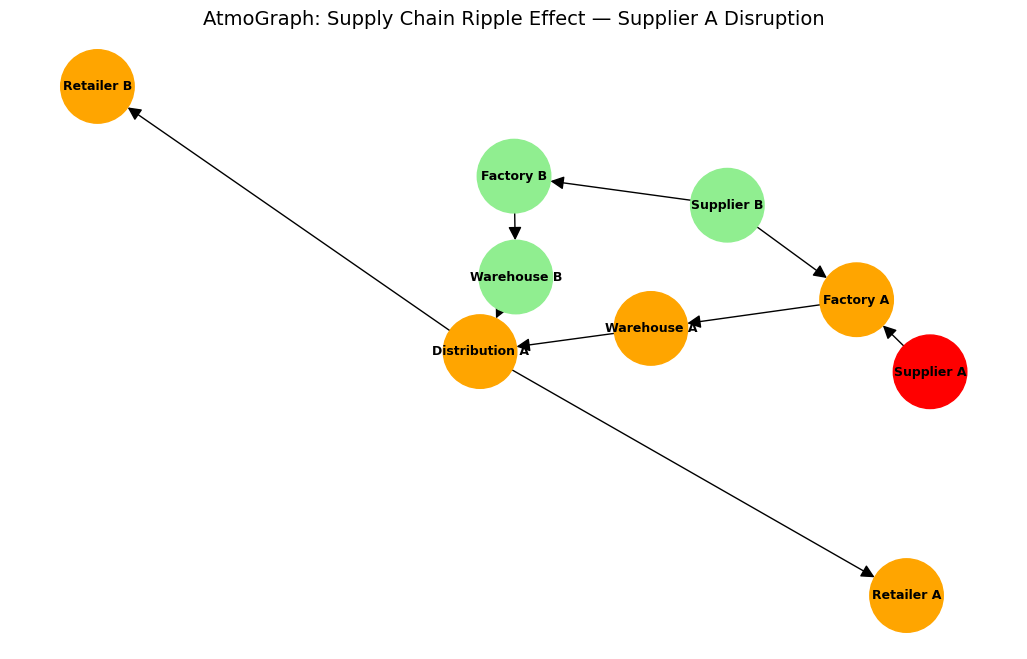

In [9]:
import matplotlib.pyplot as plt
import networkx as nx

# Assign colors based on disruption impact
node_colors = []

for node in G.nodes():

    if node == disrupted_supplier:
        node_colors.append("red")

    elif node in affected_entities:
        node_colors.append("orange")

    else:
        node_colors.append("lightgreen")

# Draw the network
plt.figure(figsize=(13, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2800,
    font_size=9,
    font_weight="bold",
    arrows=True,
    arrowsize=20
)

plt.title(
    "AtmoGraph: Supply Chain Ripple Effect — Supplier A Disruption",
    fontsize=14
)

plt.axis("off")
plt.show()

In [10]:
# Calculate downstream impact
total_nodes = G.number_of_nodes()
affected_count = len(affected_entities) - 1

ripple_impact_score = (
    affected_count / (total_nodes - 1)
) * 100

# Classify the impact
if ripple_impact_score < 30:
    impact_level = "Low"
elif ripple_impact_score < 60:
    impact_level = "Medium"
else:
    impact_level = "High"

print("ATMOgraph — RIPPLE IMPACT SCORE")
print("--------------------------------")
print("Disrupted Supplier:", disrupted_supplier)
print("Total Network Locations:", total_nodes)
print("Affected Downstream Locations:", affected_count)
print("Ripple Impact Score:", round(ripple_impact_score, 2), "%")
print("Impact Level:", impact_level)

ATMOgraph — RIPPLE IMPACT SCORE
--------------------------------
Disrupted Supplier: Supplier A
Total Network Locations: 9
Affected Downstream Locations: 5
Ripple Impact Score: 62.5 %
Impact Level: High


In [11]:
import pandas as pd
import networkx as nx

supplier_nodes = ["Supplier A", "Supplier B"]

comparison_results = []

for supplier in supplier_nodes:

    affected = nx.descendants(G, supplier)

    impact_score = (
        len(affected) / (G.number_of_nodes() - 1)
    ) * 100

    comparison_results.append({
        "Disrupted Supplier": supplier,
        "Affected Locations": len(affected),
        "Ripple Impact Score (%)": round(impact_score, 2)
    })

supplier_comparison_df = pd.DataFrame(comparison_results)

display(supplier_comparison_df)

# Identify the higher-impact supplier
highest_impact_supplier = supplier_comparison_df.loc[
    supplier_comparison_df["Ripple Impact Score (%)"].idxmax(),
    "Disrupted Supplier"
]

print("Highest-impact disruption:", highest_impact_supplier)

,Disrupted Supplier,Affected Locations,Ripple Impact Score (%)
0,Supplier A,5,62.5
1,Supplier B,7,87.5


Highest-impact disruption: Supplier B


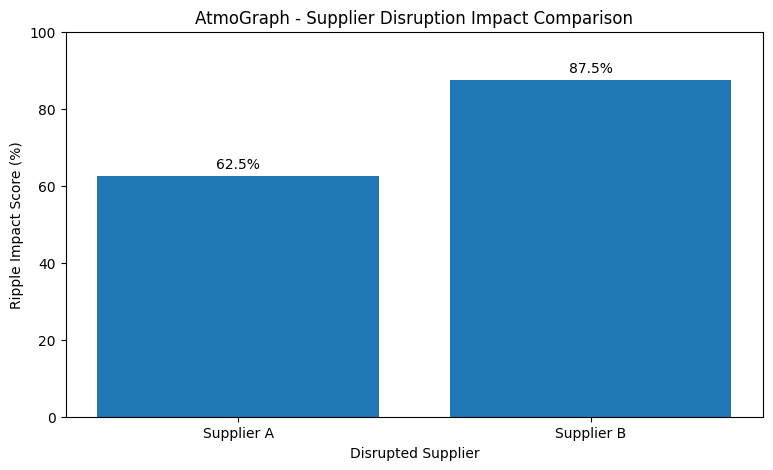

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    supplier_comparison_df["Disrupted Supplier"],
    supplier_comparison_df["Ripple Impact Score (%)"]
)

plt.title("AtmoGraph - Supplier Disruption Impact Comparison")
plt.xlabel("Disrupted Supplier")
plt.ylabel("Ripple Impact Score (%)")
plt.ylim(0, 100)

for i, value in enumerate(
    supplier_comparison_df["Ripple Impact Score (%)"]
):
    plt.text(i, value + 2, f"{value:.1f}%", ha="center")

plt.show()


In [13]:

# Simulate simultaneous disruption of both suppliers
disrupted_suppliers = ["Supplier A", "Supplier B"]

combined_affected = set()

for supplier in disrupted_suppliers:
    combined_affected.update(nx.descendants(G, supplier))

# Calculate unique affected downstream locations
total_affected = len(combined_affected)

ripple_score = (
    total_affected / (G.number_of_nodes() - len(disrupted_suppliers))
) * 100

print("ATMOgraph — COMBINED DISRUPTION ANALYSIS")
print("----------------------------------------")
print("Disrupted suppliers:", disrupted_suppliers)
print("Affected downstream locations:", total_affected)
print("Affected locations:", sorted(combined_affected))
print("Combined ripple impact score:", round(ripple_score, 2), "%")

ATMOgraph — COMBINED DISRUPTION ANALYSIS
----------------------------------------
Disrupted suppliers: ['Supplier A', 'Supplier B']
Affected downstream locations: 7
Affected locations: ['Distribution A', 'Factory A', 'Factory B', 'Retailer A', 'Retailer B', 'Warehouse A', 'Warehouse B']
Combined ripple impact score: 100.0 %


In [14]:
# Evaluate inventory vulnerability across the network

risk_results = []

for location, buffer_days in inventory_buffer.items():

    if buffer_days < disruption_duration:
        risk_level = "High Risk"
    elif buffer_days == disruption_duration:
        risk_level = "Medium Risk"
    else:
        risk_level = "Low Risk"

    risk_results.append({
        "Location": location,
        "Inventory Buffer (Days)": buffer_days,
        "Disruption Duration (Days)": disruption_duration,
        "Risk Level": risk_level
    })

risk_df = pd.DataFrame(risk_results)

# Sort locations by lowest inventory buffer
risk_df = risk_df.sort_values(
    by="Inventory Buffer (Days)"
)

display(risk_df)

print("MOST VULNERABLE LOCATION:")
print(risk_df.iloc[0]["Location"])

,Location,Inventory Buffer (Days),Disruption Duration (Days),Risk Level
2,Warehouse A,2,5,High Risk
6,Retailer B,2,5,High Risk
0,Factory A,3,5,High Risk
4,Distribution A,4,5,High Risk
5,Retailer A,5,5,Medium Risk
3,Warehouse B,6,5,Low Risk
1,Factory B,7,5,Low Risk


MOST VULNERABLE LOCATION:
Warehouse A


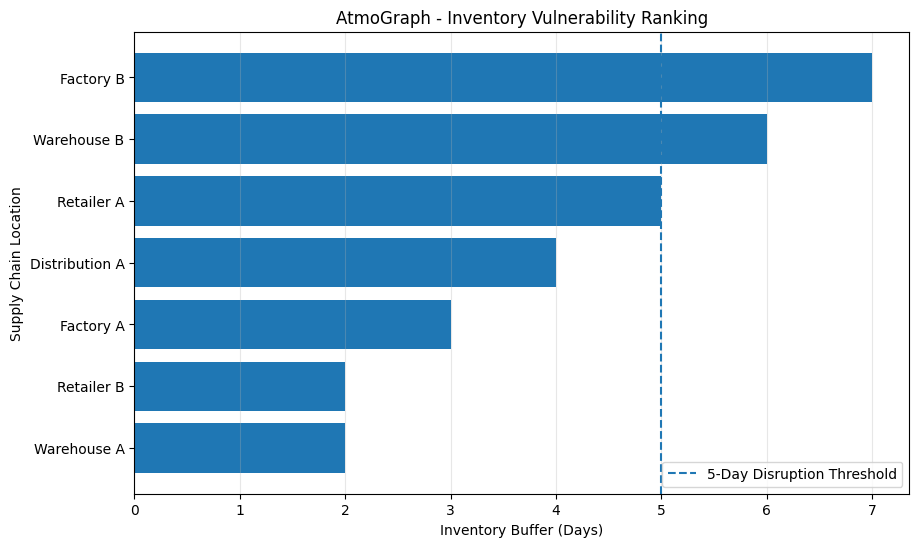

In [15]:
import matplotlib.pyplot as plt

risk_plot_df = risk_df.sort_values(
    by="Inventory Buffer (Days)",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    risk_plot_df["Location"],
    risk_plot_df["Inventory Buffer (Days)"]
)

plt.axvline(
    x=disruption_duration,
    linestyle="--",
    label="5-Day Disruption Threshold"
)

plt.title("AtmoGraph - Inventory Vulnerability Ranking")
plt.xlabel("Inventory Buffer (Days)")
plt.ylabel("Supply Chain Location")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.show()

In [16]:
# Prepare data for the delivery-risk prediction model

target = "Late_delivery_risk"

candidate_features = [
    "Type",
    "Shipping Mode",
    "Market",
    "Customer Segment",
    "Category Name",
    "Order Region",
    "Order Country",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Profit Ratio",
    "Order Item Total",
    "Days for shipment (scheduled)"
]

features = [col for col in candidate_features if col in df.columns]

model_df = df[features + [target]].copy()
model_df = model_df.dropna(subset=[target])

# Fill missing values
for col in model_df.columns:
    if model_df[col].dtype == "object":
        model_df[col] = model_df[col].fillna("Unknown")
    else:
        model_df[col] = model_df[col].fillna(model_df[col].median())

print("ML dataset restored!")
print("Rows:", model_df.shape[0])
print("Features:", len(features))
print("Target:", target)

ML dataset restored!
Rows: 180519
Features: 14
Target: Late_delivery_risk


In [17]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["Late_delivery_risk"])
y = model_df["Late_delivery_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATA SPLIT SUCCESSFUL!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

DATA SPLIT SUCCESSFUL!
Training records: 144415
Testing records: 36104
Training features: 14
Testing features: 14


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            "passthrough",
            numerical_cols
        )
    ]
)

# Fit on training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("FEATURE ENCODING SUCCESSFUL!")
print("Categorical columns:", len(categorical_cols))
print("Numerical columns:", len(numerical_cols))
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)


FEATURE ENCODING SUCCESSFUL!
Categorical columns: 7
Numerical columns: 7
Encoded training shape: (144415, 260)
Encoded testing shape: (36104, 260)


In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

print("ATMOgraph ML MODEL TRAINED SUCCESSFULLY!")
print("Algorithm: Random Forest Classifier")
print("Number of trees:", 100)
print("Maximum tree depth:", 15)

ATMOgraph ML MODEL TRAINED SUCCESSFULLY!
Algorithm: Random Forest Classifier
Number of trees: 100
Maximum tree depth: 15


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred = rf_model.predict(X_test_encoded)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("ATMOgraph MODEL EVALUATION")
print("--------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))


ATMOgraph MODEL EVALUATION
--------------------------
Accuracy : 0.7
Precision: 0.8452
Recall   : 0.5544
F1 Score : 0.6696

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.55      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.69     36104


CONFUSION MATRIX
[[14298  2010]
 [ 8822 10974]]


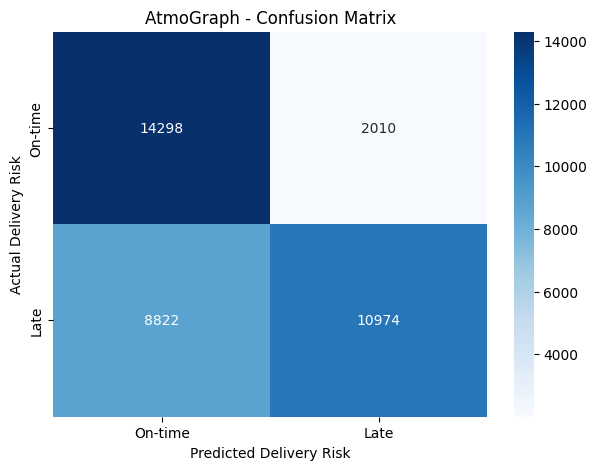

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize results
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On-time", "Late"],
    yticklabels=["On-time", "Late"]
)

plt.title("AtmoGraph - Confusion Matrix")
plt.xlabel("Predicted Delivery Risk")
plt.ylabel("Actual Delivery Risk")
plt.show()

,Feature,Importance
259,numerical__Days for shipment (scheduled),0.294529
7,categorical__Shipping Mode_Standard Class,0.234126
4,categorical__Shipping Mode_First Class,0.202013
6,categorical__Shipping Mode_Second Class,0.104820
5,categorical__Shipping Mode_Same Day,0.026775
3,categorical__Type_TRANSFER,0.018461
257,numerical__Order Item Profit Ratio,0.013617
258,numerical__Order Item Total,0.012404
255,numerical__Order Item Discount,0.011769
256,numerical__Order Item Discount Rate,0.009635


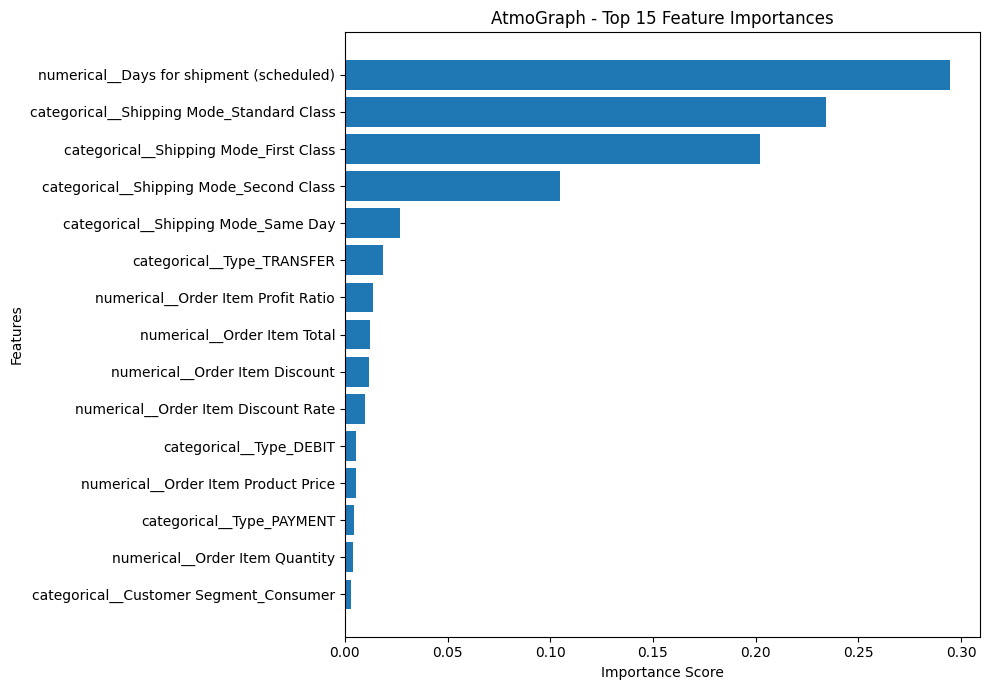

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Get encoded feature names
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
top_features = importance_df.head(15)

display(top_features)

# Visualize
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("AtmoGraph - Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [23]:
# Check for columns that reveal actual delivery outcomes

leakage_candidates = [
    "Days for shipping (real)",
    "Delivery Status",
    "Late_delivery_risk",
    "Delay_Days",
    "Late_delivery"
]

print("ATMOgraph — DATA LEAKAGE AUDIT")
print("--------------------------------")

print("Current model features:")
print(list(X_train.columns))

print("\nPotential leakage columns:")
for col in leakage_candidates:
    if col in X_train.columns:
        print("WARNING: Found in model features:", col)
    else:
        print("SAFE: Not included in model features:", col)

ATMOgraph — DATA LEAKAGE AUDIT
--------------------------------
Current model features:
['Type', 'Shipping Mode', 'Market', 'Customer Segment', 'Category Name', 'Order Region', 'Order Country', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Total', 'Days for shipment (scheduled)']

Potential leakage columns:
SAFE: Not included in model features: Days for shipping (real)
SAFE: Not included in model features: Delivery Status
SAFE: Not included in model features: Late_delivery_risk
SAFE: Not included in model features: Delay_Days
SAFE: Not included in model features: Late_delivery


In [24]:
# Check for columns that reveal actual delivery outcomes

leakage_candidates = [
    "Days for shipping (real)",
    "Delivery Status",
    "Late_delivery_risk",
    "Delay_Days",
    "Late_delivery"
]

print("ATMOgraph — DATA LEAKAGE AUDIT")
print("--------------------------------")

print("Current model features:")
print(list(X_train.columns))

print("\nPotential leakage columns:")
for col in leakage_candidates:
    if col in X_train.columns:
        print("WARNING: Found in model features:", col)
    else:
        print("SAFE: Not included in model features:", col)

ATMOgraph — DATA LEAKAGE AUDIT
--------------------------------
Current model features:
['Type', 'Shipping Mode', 'Market', 'Customer Segment', 'Category Name', 'Order Region', 'Order Country', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Total', 'Days for shipment (scheduled)']

Potential leakage columns:
SAFE: Not included in model features: Days for shipping (real)
SAFE: Not included in model features: Delivery Status
SAFE: Not included in model features: Late_delivery_risk
SAFE: Not included in model features: Delay_Days
SAFE: Not included in model features: Late_delivery


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Separate features and target
X_safe = safe_df.drop(columns=["Late_delivery_risk"])
y_safe = safe_df["Late_delivery_risk"]

# Split the data
X_train_safe, X_test_safe, y_train_safe, y_test_safe = train_test_split(
    X_safe,
    y_safe,
    test_size=0.20,
    random_state=42,
    stratify=y_safe
)

# Identify column types
cat_cols = X_train_safe.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_train_safe.select_dtypes(include=["number"]).columns.tolist()

# Encode categorical features
safe_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols)
])

X_train_safe_encoded = safe_preprocessor.fit_transform(X_train_safe)
X_test_safe_encoded = safe_preprocessor.transform(X_test_safe)

# Train revised model
safe_rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

safe_rf_model.fit(X_train_safe_encoded, y_train_safe)

print("SAFER ATMOgraph MODEL TRAINED!")
print("Training records:", len(X_train_safe))
print("Testing records:", len(X_test_safe))
print("Encoded features:", X_train_safe_encoded.shape[1])

NameError: name 'safe_df' is not defined

In [26]:
safe_features = [
    "Type",
    "Market",
    "Customer Segment",
    "Category Name",
    "Order Region",
    "Order Country",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Total",
    "Shipping Mode",
    "Days for shipment (scheduled)"
]

safe_features = [
    col for col in safe_features if col in df.columns
]

safe_df = df[safe_features + ["Late_delivery_risk"]].copy()

safe_df = safe_df.dropna(subset=["Late_delivery_risk"])

for col in safe_df.columns:
    if safe_df[col].dtype == "object":
        safe_df[col] = safe_df[col].fillna("Unknown")
    else:
        safe_df[col] = safe_df[col].fillna(safe_df[col].median())

print("SAFER DATASET CREATED!")
print("Rows:", safe_df.shape[0])
print("Features:", len(safe_features))

SAFER DATASET CREATED!
Rows: 180519
Features: 13


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Separate features and target
X_safe = safe_df.drop(columns=["Late_delivery_risk"])
y_safe = safe_df["Late_delivery_risk"]

# Split dataset
X_train_safe, X_test_safe, y_train_safe, y_test_safe = train_test_split(
    X_safe,
    y_safe,
    test_size=0.20,
    random_state=42,
    stratify=y_safe
)

# Identify data types
cat_cols = X_train_safe.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_train_safe.select_dtypes(include=["number"]).columns.tolist()

# Encode categorical features
safe_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols)
])

X_train_safe_encoded = safe_preprocessor.fit_transform(X_train_safe)
X_test_safe_encoded = safe_preprocessor.transform(X_test_safe)

# Train model
safe_rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

safe_rf_model.fit(X_train_safe_encoded, y_train_safe)

print("SAFER ATMOgraph MODEL TRAINED!")
print("Training records:", len(X_train_safe))
print("Testing records:", len(X_test_safe))
print("Encoded features:", X_train_safe_encoded.shape[1])


SAFER ATMOgraph MODEL TRAINED!
Training records: 144415
Testing records: 36104
Encoded features: 259


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict using the revised model
y_safe_pred = safe_rf_model.predict(X_test_safe_encoded)

# Calculate metrics
print("ATMOgraph — REVISED MODEL EVALUATION")
print("------------------------------------")

print("Accuracy :", round(accuracy_score(y_test_safe, y_safe_pred), 4))
print("Precision:", round(precision_score(y_test_safe, y_safe_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test_safe, y_safe_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test_safe, y_safe_pred, zero_division=0), 4))

print("\nDetailed Classification Report:")
print(classification_report(y_test_safe, y_safe_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_safe, y_safe_pred))

ATMOgraph — REVISED MODEL EVALUATION
------------------------------------
Accuracy : 0.6997
Precision: 0.8412
Recall   : 0.5576
F1 Score : 0.6706

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.87      0.72     16308
           1       0.84      0.56      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.70     36104
weighted avg       0.74      0.70      0.69     36104


Confusion Matrix:
[[14224  2084]
 [ 8758 11038]]


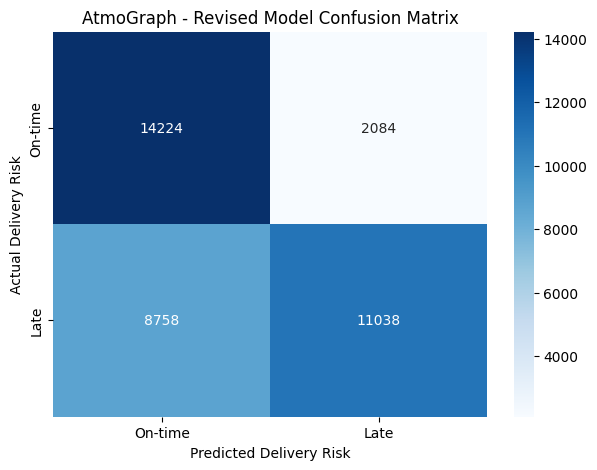

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_safe = confusion_matrix(y_test_safe, y_safe_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_safe,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On-time", "Late"],
    yticklabels=["On-time", "Late"]
)

plt.title("AtmoGraph - Revised Model Confusion Matrix")
plt.xlabel("Predicted Delivery Risk")
plt.ylabel("Actual Delivery Risk")
plt.show()

In [30]:
import os
import joblib

# Create model directory
os.makedirs("/content/AtmoGraph/models", exist_ok=True)

# Save trained model
joblib.dump(
    safe_rf_model,
    "/content/AtmoGraph/models/atmograph_random_forest.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    safe_preprocessor,
    "/content/AtmoGraph/models/atmograph_preprocessor.pkl"
)

print("ATMOgraph MODEL SAVED SUCCESSFULLY!")
print("1. Random Forest Model")
print("2. Preprocessing Pipeline")

ATMOgraph MODEL SAVED SUCCESSFULLY!
1. Random Forest Model
2. Preprocessing Pipeline


In [31]:
def predict_delivery_risk(order_details):

    # Convert input into a DataFrame
    new_order = pd.DataFrame([order_details])

    # Apply the same preprocessing used during training
    encoded_order = safe_preprocessor.transform(new_order)

    # Predict risk
    prediction = safe_rf_model.predict(encoded_order)[0]

    # Get probability estimate
    probability = safe_rf_model.predict_proba(encoded_order)[0][1]

    # Display result
    print("ATMOgraph DELIVERY RISK PREDICTION")
    print("---------------------------------")
    print("Prediction:", "Late Delivery Risk" if prediction == 1 else "Low Delivery Risk")
    print("Estimated Risk Score:", round(probability * 100, 2), "%")

    return probability

In [32]:
sample_order = {
    "Type": "DEBIT",
    "Market": "Europe",
    "Customer Segment": "Consumer",
    "Category Name": "Sporting Goods",
    "Order Region": "Western Europe",
    "Order Country": "France",
    "Order Item Quantity": 2,
    "Order Item Product Price": 327.75,
    "Order Item Discount": 10.0,
    "Order Item Discount Rate": 0.1,
    "Order Item Total": 589.95,
    "Shipping Mode": "Standard Class",
    "Days for shipment (scheduled)": 4
}

risk_probability = predict_delivery_risk(sample_order)

ATMOgraph DELIVERY RISK PREDICTION
---------------------------------
Prediction: Low Delivery Risk
Estimated Risk Score: 37.28 %


In [33]:
!pip install gradio -q

print("Gradio installed successfully!")

Gradio installed successfully!


In [34]:
import gradio as gr
import pandas as pd

def atmograph_dashboard(
    order_type,
    market,
    customer_segment,
    category,
    region,
    country,
    quantity,
    product_price,
    discount,
    discount_rate,
    order_total,
    shipping_mode,
    scheduled_days
):

    order_details = {
        "Type": order_type,
        "Market": market,
        "Customer Segment": customer_segment,
        "Category Name": category,
        "Order Region": region,
        "Order Country": country,
        "Order Item Quantity": quantity,
        "Order Item Product Price": product_price,
        "Order Item Discount": discount,
        "Order Item Discount Rate": discount_rate,
        "Order Item Total": order_total,
        "Shipping Mode": shipping_mode,
        "Days for shipment (scheduled)": scheduled_days
    }

    probability = predict_delivery_risk(order_details)

    prediction = (
        "HIGHER LATE-DELIVERY RISK"
        if probability >= 0.5
        else "LOWER LATE-DELIVERY RISK"
    )

    return prediction, f"{probability * 100:.2f}%"

demo = gr.Interface(
    fn=atmograph_dashboard,
    inputs=[
        gr.Textbox(value="DEBIT", label="Order Type"),
        gr.Textbox(value="Europe", label="Market"),
        gr.Textbox(value="Consumer", label="Customer Segment"),
        gr.Textbox(value="Sporting Goods", label="Product Category"),
        gr.Textbox(value="Western Europe", label="Order Region"),
        gr.Textbox(value="France", label="Order Country"),
        gr.Number(value=2, label="Order Quantity"),
        gr.Number(value=327.75, label="Product Price"),
        gr.Number(value=10, label="Discount"),
        gr.Number(value=0.1, label="Discount Rate"),
        gr.Number(value=589.95, label="Order Total"),
        gr.Dropdown(
            ["First Class", "Same Day", "Second Class", "Standard Class"],
            value="Standard Class",
            label="Shipping Mode"
        ),
        gr.Number(value=4, label="Scheduled Shipping Days")
    ],
    outputs=[
        gr.Textbox(label="AtmoGraph Prediction"),
        gr.Textbox(label="Estimated Risk Score")
    ],
    title="AtmoGraph — AI Supply Chain Risk Predictor",
    description="Enter order details to estimate late-delivery risk."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://63cb18bf80a1e9ef29.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [36]:
def simulate_supplier_disruption(supplier_name):

    # Identify downstream affected locations
    affected = nx.descendants(G, supplier_name)

    # Calculate ripple impact
    impact_score = (
        len(affected) / (G.number_of_nodes() - 1)
    ) * 100

    print("ATMOgraph — DISRUPTION SIMULATOR")
    print("--------------------------------")
    print("Disrupted Supplier:", supplier_name)
    print("Affected Locations:", len(affected))
    print("Ripple Impact Score:", round(impact_score, 2), "%")

    print("\nAffected Supply Chain Locations:")

    for location in sorted(affected):
        print("-", location)

    return affected, impact_score

In [37]:
affected, impact = simulate_supplier_disruption("Supplier B")

ATMOgraph — DISRUPTION SIMULATOR
--------------------------------
Disrupted Supplier: Supplier B
Affected Locations: 7
Ripple Impact Score: 87.5 %

Affected Supply Chain Locations:
- Distribution A
- Factory A
- Factory B
- Retailer A
- Retailer B
- Warehouse A
- Warehouse B


In [38]:
def atmograph_combined_analysis(order_details, supplier_name):

    # 1. Predict delivery risk
    new_order = pd.DataFrame([order_details])
    encoded_order = safe_preprocessor.transform(new_order)

    risk_probability = safe_rf_model.predict_proba(
        encoded_order
    )[0][1]

    # 2. Simulate supplier disruption
    affected_locations = nx.descendants(G, supplier_name)

    ripple_score = (
        len(affected_locations) / (G.number_of_nodes() - 1)
    ) * 100

    # 3. Generate combined result
    print("======================================")
    print("       ATMOgraph AI ANALYSIS")
    print("======================================")

    print("\nDELIVERY RISK")
    print("Estimated Risk:", round(risk_probability * 100, 2), "%")

    print("\nSUPPLY CHAIN DISRUPTION")
    print("Disrupted Supplier:", supplier_name)
    print("Affected Locations:", len(affected_locations))
    print("Ripple Impact:", round(ripple_score, 2), "%")

    print("\nAFFECTED LOCATIONS")

    for location in sorted(affected_locations):
        print("-", location)

    return {
        "delivery_risk": risk_probability,
        "ripple_impact": ripple_score,
        "affected_locations": sorted(affected_locations)
    }

In [39]:
def atmograph_combined_analysis(order_details, supplier_name):

    # 1. Predict delivery risk
    new_order = pd.DataFrame([order_details])
    encoded_order = safe_preprocessor.transform(new_order)

    risk_probability = safe_rf_model.predict_proba(
        encoded_order
    )[0][1]

    # 2. Simulate supplier disruption
    affected_locations = nx.descendants(G, supplier_name)

    ripple_score = (
        len(affected_locations) / (G.number_of_nodes() - 1)
    ) * 100

    # 3. Generate combined result
    print("======================================")
    print("       ATMOgraph AI ANALYSIS")
    print("======================================")

    print("\nDELIVERY RISK")
    print("Estimated Risk:", round(risk_probability * 100, 2), "%")

    print("\nSUPPLY CHAIN DISRUPTION")
    print("Disrupted Supplier:", supplier_name)
    print("Affected Locations:", len(affected_locations))
    print("Ripple Impact:", round(ripple_score, 2), "%")

    print("\nAFFECTED LOCATIONS")

    for location in sorted(affected_locations):
        print("-", location)

    return {
        "delivery_risk": risk_probability,
        "ripple_impact": ripple_score,
        "affected_locations": sorted(affected_locations)
    }

In [40]:
sample_order = {
    "Type": "DEBIT",
    "Market": "Europe",
    "Customer Segment": "Consumer",
    "Category Name": "Sporting Goods",
    "Order Region": "Western Europe",
    "Order Country": "France",
    "Order Item Quantity": 2,
    "Order Item Product Price": 327.75,
    "Order Item Discount": 10.0,
    "Order Item Discount Rate": 0.1,
    "Order Item Total": 589.95,
    "Shipping Mode": "Standard Class",
    "Days for shipment (scheduled)": 4
}

combined_result = atmograph_combined_analysis(
    sample_order,
    "Supplier A"
)

print("\nATMOgraph TEST COMPLETED!")

       ATMOgraph AI ANALYSIS

DELIVERY RISK
Estimated Risk: 37.28 %

SUPPLY CHAIN DISRUPTION
Disrupted Supplier: Supplier A
Affected Locations: 5
Ripple Impact: 62.5 %

AFFECTED LOCATIONS
- Distribution A
- Factory A
- Retailer A
- Retailer B
- Warehouse A

ATMOgraph TEST COMPLETED!


In [41]:
print("ATMOgraph SYSTEM STATUS")
print("-----------------------")

print("Dataset loaded:", "df" in globals())
print("ML model available:", "safe_rf_model" in globals())
print("Preprocessor available:", "safe_preprocessor" in globals())
print("Supply chain network available:", "G" in globals())
print("Inventory data available:", "inventory_buffer" in globals())
print("Combined analysis function available:",
      "atmograph_combined_analysis" in globals())

print("\nNetwork nodes:", G.number_of_nodes())
print("Network connections:", G.number_of_edges())
print("\nSYSTEM CHECK COMPLETED!")

ATMOgraph SYSTEM STATUS
-----------------------
Dataset loaded: True
ML model available: True
Preprocessor available: True
Supply chain network available: True
Inventory data available: True
Combined analysis function available: True

Network nodes: 9
Network connections: 9

SYSTEM CHECK COMPLETED!


In [42]:
# Step 68: Inventory-aware disruption analysis

disrupted_supplier = "Supplier A"
disruption_duration = 5

affected_locations = nx.descendants(
    G, disrupted_supplier
)

inventory_risk_results = []

for location in sorted(affected_locations):

    buffer_days = inventory_buffer.get(location, 0)

    shortage_days = max(
        0,
        disruption_duration - buffer_days
    )

    if shortage_days == 0:
        status = "Protected"
    else:
        status = "Inventory Shortage Risk"

    inventory_risk_results.append({
        "Location": location,
        "Inventory Buffer (Days)": buffer_days,
        "Disruption Duration (Days)": disruption_duration,
        "Potential Shortage (Days)": shortage_days,
        "Risk Status": status
    })

inventory_impact_df = pd.DataFrame(
    inventory_risk_results
)

display(inventory_impact_df)

print("ATMOgraph INVENTORY-AWARE IMPACT ANALYSIS")
print("-----------------------------------------")
print("Disrupted Supplier:", disrupted_supplier)
print("Affected Locations:", len(affected_locations))
print(
    "Locations at inventory shortage risk:",
    (inventory_impact_df["Potential Shortage (Days)"] > 0).sum()
)


,Location,Inventory Buffer (Days),Disruption Duration (Days),Potential Shortage (Days),Risk Status
0,Distribution A,4,5,1,Inventory Shortage Risk
1,Factory A,3,5,2,Inventory Shortage Risk
2,Retailer A,5,5,0,Protected
3,Retailer B,2,5,3,Inventory Shortage Risk
4,Warehouse A,2,5,3,Inventory Shortage Risk


ATMOgraph INVENTORY-AWARE IMPACT ANALYSIS
-----------------------------------------
Disrupted Supplier: Supplier A
Affected Locations: 5
Locations at inventory shortage risk: 4


In [43]:
# Step 69: Intervention Priority Ranking

priority_df = inventory_impact_df.copy()

priority_df["Priority"] = priority_df[
    "Potential Shortage (Days)"
].apply(
    lambda days: (
        "Critical" if days >= 3
        else "High" if days >= 2
        else "Medium" if days >= 1
        else "Low"
    )
)

priority_df = priority_df.sort_values(
    by="Potential Shortage (Days)",
    ascending=False
).reset_index(drop=True)

priority_df.insert(
    0,
    "Priority Rank",
    range(1, len(priority_df) + 1)
)

display(priority_df)

print("\nATMOgraph INTERVENTION PRIORITY REPORT")
print("--------------------------------------")

for _, row in priority_df.iterrows():
    print(
        f"{row['Priority Rank']}. {row['Location']} "
        f"→ {row['Priority']} Priority "
        f"({row['Potential Shortage (Days)']} shortage days)"
    )



,Priority Rank,Location,Inventory Buffer (Days),Disruption Duration (Days),Potential Shortage (Days),Risk Status,Priority
0,1,Warehouse A,2,5,3,Inventory Shortage Risk,Critical
1,2,Retailer B,2,5,3,Inventory Shortage Risk,Critical
2,3,Factory A,3,5,2,Inventory Shortage Risk,High
3,4,Distribution A,4,5,1,Inventory Shortage Risk,Medium
4,5,Retailer A,5,5,0,Protected,Low



ATMOgraph INTERVENTION PRIORITY REPORT
--------------------------------------
1. Warehouse A → Critical Priority (3 shortage days)
2. Retailer B → Critical Priority (3 shortage days)
3. Factory A → High Priority (2 shortage days)
4. Distribution A → Medium Priority (1 shortage days)
5. Retailer A → Low Priority (0 shortage days)


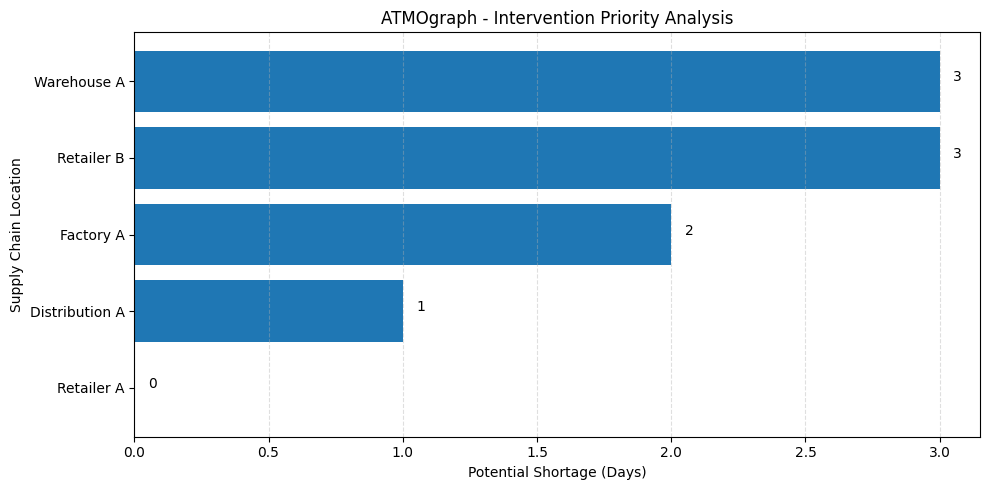

In [44]:
# Step 70: AtmoGraph Intervention Priority Visualization

plt.figure(figsize=(10, 5))

plt.barh(
    priority_df["Location"],
    priority_df["Potential Shortage (Days)"]
)

plt.xlabel("Potential Shortage (Days)")
plt.ylabel("Supply Chain Location")
plt.title("ATMOgraph - Intervention Priority Analysis")

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)

for index, value in enumerate(
    priority_df["Potential Shortage (Days)"]
):
    plt.text(value + 0.05, index, str(value))

plt.tight_layout()
plt.show()

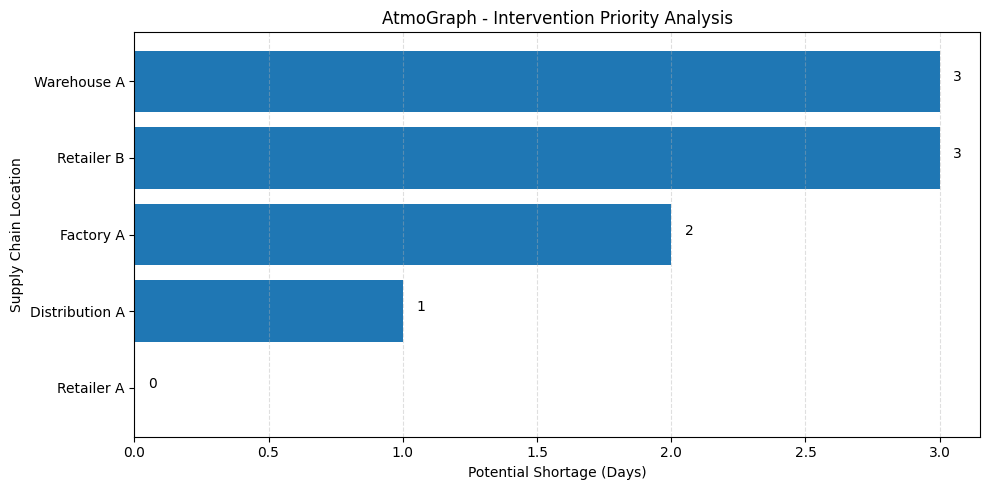

Chart saved successfully: /content/AtmoGraph/outputs/AtmoGraph_Intervention_Priority.png


In [45]:
# Step 71: Save AtmoGraph Priority Chart

import os

output_folder = "/content/AtmoGraph/outputs"
os.makedirs(output_folder, exist_ok=True)

chart_path = os.path.join(
    output_folder,
    "AtmoGraph_Intervention_Priority.png"
)

plt.figure(figsize=(10, 5))

plt.barh(
    priority_df["Location"],
    priority_df["Potential Shortage (Days)"]
)

plt.xlabel("Potential Shortage (Days)")
plt.ylabel("Supply Chain Location")
plt.title("AtmoGraph - Intervention Priority Analysis")

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)

for index, value in enumerate(
    priority_df["Potential Shortage (Days)"]
):
    plt.text(value + 0.05, index, str(value))

plt.tight_layout()
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully:", chart_path)

In [46]:
!pip install gradio -q

import gradio as gr

print("Gradio version:", gr.__version__)
print("ATMOgraph dashboard environment ready!")

Gradio version: 6.31.0
ATMOgraph dashboard environment ready!


In [47]:
# STEP 73: ATMOgraph Combined Interactive Dashboard

import gradio as gr
import pandas as pd
import networkx as nx

def run_atmograph(
    order_type,
    market,
    customer_segment,
    category,
    region,
    country,
    quantity,
    price,
    discount,
    discount_rate,
    order_total,
    shipping_mode,
    scheduled_days,
    supplier
):

    try:
        order_details = {
            "Type": order_type,
            "Market": market,
            "Customer Segment": customer_segment,
            "Category Name": category,
            "Order Region": region,
            "Order Country": country,
            "Order Item Quantity": quantity,
            "Order Item Product Price": price,
            "Order Item Discount": discount,
            "Order Item Discount Rate": discount_rate,
            "Order Item Total": order_total,
            "Shipping Mode": shipping_mode,
            "Days for shipment (scheduled)": scheduled_days
        }

        # 1. Delivery risk prediction
        order_df = pd.DataFrame([order_details])
        encoded_order = safe_preprocessor.transform(order_df)

        risk_probability = safe_rf_model.predict_proba(
            encoded_order
        )[0][1]

        prediction = (
            "Late Delivery Risk"
            if risk_probability >= 0.5
            else "Low Delivery Risk"
        )

        # 2. Supplier disruption analysis
        affected_locations = nx.descendants(G, supplier)

        ripple_score = (
            len(affected_locations) /
            (G.number_of_nodes() - 1)
        ) * 100

        # 3. Inventory intervention analysis
        results = []

        for location in sorted(affected_locations):

            buffer_days = inventory_buffer.get(location, 0)
            shortage_days = max(0, 5 - buffer_days)

            if shortage_days >= 3:
                priority = "Critical"
            elif shortage_days >= 2:
                priority = "High"
            elif shortage_days >= 1:
                priority = "Medium"
            else:
                priority = "Low"

            results.append({
                "Location": location,
                "Inventory Buffer (Days)": buffer_days,
                "Potential Shortage (Days)": shortage_days,
                "Priority": priority
            })

        result_df = pd.DataFrame(results)

        if not result_df.empty:
            result_df = result_df.sort_values(
                by="Potential Shortage (Days)",
                ascending=False
            ).reset_index(drop=True)

        report = f"""
ATMOgraph - SUPPLY CHAIN INTELLIGENCE REPORT

DELIVERY RISK
Prediction: {prediction}
Estimated Model Score: {risk_probability * 100:.2f}%

SUPPLIER DISRUPTION
Disrupted Supplier: {supplier}
Affected Locations: {len(affected_locations)}
Ripple Impact Score: {ripple_score:.2f}%

INVENTORY INTERVENTION
Critical/High priority locations:
{(result_df['Priority'].isin(['Critical', 'High'])).sum() if not result_df.empty else 0}

Note: Inventory buffers, disruption duration and network connections
are illustrative simulation assumptions. The model score is not
a calibrated real-world probability.
"""

        return report, result_df

    except Exception as e:
        return f"Dashboard error: {str(e)}", pd.DataFrame()


with gr.Blocks(title="AtmoGraph Supply Chain Intelligence") as demo:

    gr.Markdown("# 🌐 ATMOgraph")
    gr.Markdown(
        "### AI-Powered Supply Chain Disruption Prediction System"
    )

    gr.Markdown("## Order Information")

    with gr.Row():
        order_type = gr.Dropdown(
            ["DEBIT", "TRANSFER", "CASH", "PAYMENT"],
            value="DEBIT",
            label="Order Type"
        )
        market = gr.Dropdown(
            ["Europe", "Pacific Asia", "USCA", "LATAM",
             "Africa", "Asia Pacific", "Middle East"],
            value="Europe",
            label="Market"
        )
        customer_segment = gr.Dropdown(
            ["Consumer", "Corporate", "Home Office"],
            value="Consumer",
            label="Customer Segment"
        )

    with gr.Row():
        category = gr.Textbox(
            value="Sporting Goods",
            label="Product Category"
        )
        region = gr.Textbox(
            value="Western Europe",
            label="Order Region"
        )
        country = gr.Textbox(
            value="France",
            label="Order Country"
        )

    gr.Markdown("## Order Details")

    with gr.Row():
        quantity = gr.Number(value=2, label="Quantity")
        price = gr.Number(value=327.75, label="Product Price")
        discount = gr.Number(value=10.0, label="Discount")

    with gr.Row():
        discount_rate = gr.Number(value=0.1, label="Discount Rate")
        order_total = gr.Number(value=589.95, label="Order Total")
        scheduled_days = gr.Number(
            value=4,
            label="Scheduled Shipping Days"
        )

    shipping_mode = gr.Dropdown(
        ["Standard Class", "Second Class", "First Class", "Same Day"],
        value="Standard Class",
        label="Shipping Mode"
    )

    gr.Markdown("## Supplier Disruption Scenario")

    supplier = gr.Dropdown(
        ["Supplier A", "Supplier B"],
        value="Supplier A",
        label="Select Disrupted Supplier"
    )

    analyze_button = gr.Button(
        "Run AtmoGraph Analysis",
        variant="primary"
    )

    gr.Markdown("## Analysis Results")

    report_output = gr.Textbox(
        label="Supply Chain Intelligence Report",
        lines=15
    )

    table_output = gr.Dataframe(
        label="Inventory Intervention Priority",
        interactive=False
    )

    analyze_button.click(
        fn=run_atmograph,
        inputs=[
            order_type,
            market,
            customer_segment,
            category,
            region,
            country,
            quantity,
            price,
            discount,
            discount_rate,
            order_total,
            scheduled_days,
            shipping_mode,
            supplier
        ],
        outputs=[report_output, table_output]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1cabfbe422aca73035.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [49]:
def run_atmograph(
    order_type,
    market,
    customer_segment,
    category,
    region,
    country,
    quantity,
    price,
    discount,
    discount_rate,
    order_total,
    shipping_mode,
    scheduled_days,
    supplier
):

    try:
        # Convert numeric inputs explicitly
        order_details = {
            "Type": str(order_type),
            "Market": str(market),
            "Customer Segment": str(customer_segment),
            "Category Name": str(category),
            "Order Region": str(region),
            "Order Country": str(country),
            "Order Item Quantity": float(quantity),
            "Order Item Product Price": float(price),
            "Order Item Discount": float(discount),
            "Order Item Discount Rate": float(discount_rate),
            "Order Item Total": float(order_total),
            "Shipping Mode": str(shipping_mode),
            "Days for shipment (scheduled)": float(scheduled_days)
        }

        # Match the exact training feature order and types
        order_df = pd.DataFrame(
            [order_details],
            columns=X_train_safe.columns
        )

        # Convert numeric columns explicitly
        for col in num_cols:
            order_df[col] = pd.to_numeric(
                order_df[col],
                errors="coerce"
            )

        # Convert categorical columns to strings
        for col in cat_cols:
            order_df[col] = order_df[col].fillna("Unknown").astype(str)

        if order_df.isnull().any().any():
            raise ValueError("Please enter valid numeric order details.")

        # 1. Delivery risk prediction
        encoded_order = safe_preprocessor.transform(order_df)

        risk_probability = safe_rf_model.predict_proba(
            encoded_order
        )[0][1]

        prediction = (
            "Late Delivery Risk"
            if risk_probability >= 0.5
            else "Low Delivery Risk"
        )

        # 2. Supplier disruption analysis
        affected_locations = nx.descendants(G, supplier)

        ripple_score = (
            len(affected_locations) /
            (G.number_of_nodes() - 1)
        ) * 100

        # 3. Inventory intervention analysis
        results = []

        for location in sorted(affected_locations):
            buffer_days = inventory_buffer.get(location, 0)
            shortage_days = max(0, 5 - buffer_days)

            if shortage_days >= 3:
                priority = "Critical"
            elif shortage_days >= 2:
                priority = "High"
            elif shortage_days >= 1:
                priority = "Medium"
            else:
                priority = "Low"

            results.append({
                "Location": location,
                "Inventory Buffer (Days)": buffer_days,
                "Potential Shortage (Days)": shortage_days,
                "Priority": priority
            })

        result_df = pd.DataFrame(results)

        if not result_df.empty:
            result_df = result_df.sort_values(
                by="Potential Shortage (Days)",
                ascending=False
            ).reset_index(drop=True)

        report = f"""
ATMOgraph - SUPPLY CHAIN INTELLIGENCE REPORT

DELIVERY RISK
Prediction: {prediction}
Estimated Model Score: {risk_probability * 100:.2f}%

SUPPLIER DISRUPTION
Disrupted Supplier: {supplier}
Affected Locations: {len(affected_locations)}
Ripple Impact Score: {ripple_score:.2f}%

INVENTORY INTERVENTION
Critical/High priority locations:
{result_df['Priority'].isin(['Critical', 'High']).sum()}

Note: Inventory and network values are illustrative simulation assumptions.
The model score is not a calibrated real-world probability.
"""

        return report, result_df

    except Exception as e:
        return f"Dashboard error: {type(e).__name__}: {str(e)}", pd.DataFrame()

In [50]:
# ATMOgraph: Preprocessing Diagnostic

print("MODEL INPUT DIAGNOSTIC")
print("----------------------")

print("\n1. Training feature columns:")
print(X_train_safe.dtypes)

print("\n2. Categorical columns:")
print(cat_cols)

print("\n3. Numerical columns:")
print(num_cols)

print("\n4. Preprocessor:")
print(safe_preprocessor)

print("\n5. Test sample data types:")
print(X_train_safe.iloc[[0]].dtypes)

print("\n6. Testing preprocessing:")
try:
    test_input = X_train_safe.iloc[[0]].copy()
    test_encoded = safe_preprocessor.transform(test_input)
    print("SUCCESS! Preprocessing works.")
    print("Encoded shape:", test_encoded.shape)

except Exception as e:
    print("PREPROCESSING FAILED:")
    print(type(e).__name__, str(e))

MODEL INPUT DIAGNOSTIC
----------------------

1. Training feature columns:
Type                              object
Market                            object
Customer Segment                  object
Category Name                     object
Order Region                      object
Order Country                     object
Order Item Quantity                int64
Order Item Product Price         float64
Order Item Discount              float64
Order Item Discount Rate         float64
Order Item Total                 float64
Shipping Mode                     object
Days for shipment (scheduled)      int64
dtype: object

2. Categorical columns:
['Type', 'Market', 'Customer Segment', 'Category Name', 'Order Region', 'Order Country', 'Shipping Mode']

3. Numerical columns:
['Order Item Quantity', 'Order Item Product Price', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Total', 'Days for shipment (scheduled)']

4. Preprocessor:
ColumnTransformer(transformers=[('cat', OneHotEnc

In [51]:
# ATMOgraph: Independent Model Prediction Test

print("MODEL PREDICTION DIAGNOSTIC")
print("---------------------------")

try:
    test_input = X_train_safe.iloc[[0]].copy()

    test_encoded = safe_preprocessor.transform(test_input)

    print("Preprocessing: SUCCESS")

    prediction = safe_rf_model.predict(test_encoded)

    print("Model prediction: SUCCESS")
    print("Predicted class:", prediction[0])

    probability = safe_rf_model.predict_proba(test_encoded)

    print("Prediction probabilities:", probability[0])
    print("\nMODEL TEST PASSED!")

except Exception as e:
    print("MODEL TEST FAILED")
    print("Error type:", type(e).__name__)
    print("Error details:", str(e))





MODEL PREDICTION DIAGNOSTIC
---------------------------
Preprocessing: SUCCESS
Model prediction: SUCCESS
Predicted class: 0
Prediction probabilities: [0.62650328 0.37349672]

MODEL TEST PASSED!


In [52]:
# STEP 79: Test AtmoGraph Combined Analysis

test_order = X_train_safe.iloc[0].to_dict()

try:
    result = atmograph_combined_analysis(
        test_order,
        "Supplier A"
    )

    print("\nCOMBINED ANALYSIS TEST PASSED!")
    print("Delivery risk:", result["delivery_risk"])
    print("Ripple impact:", result["ripple_impact"])
    print("Affected locations:", result["affected_locations"])

except Exception as e:
    print("COMBINED ANALYSIS FAILED")
    print(type(e).__name__, str(e))

       ATMOgraph AI ANALYSIS

DELIVERY RISK
Estimated Risk: 37.35 %

SUPPLY CHAIN DISRUPTION
Disrupted Supplier: Supplier A
Affected Locations: 5
Ripple Impact: 62.5 %

AFFECTED LOCATIONS
- Distribution A
- Factory A
- Retailer A
- Retailer B
- Warehouse A

COMBINED ANALYSIS TEST PASSED!
Delivery risk: 0.37349671720298594
Ripple impact: 62.5
Affected locations: ['Distribution A', 'Factory A', 'Retailer A', 'Retailer B', 'Warehouse A']


In [53]:
# STEP 80: Test the verified dashboard backend

def atmograph_dashboard_backend(supplier):

    result = atmograph_combined_analysis(
        X_train_safe.iloc[0].to_dict(),
        supplier
    )

    report = f"""
ATMOgraph AI SUPPLY CHAIN REPORT

Supplier: {supplier}

Delivery Risk:
{result['delivery_risk'] * 100:.2f}%

Ripple Impact:
{result['ripple_impact']:.2f}%

Affected Locations:
"""

    for location in result["affected_locations"]:
        report += f"\n- {location}"

    return report


# Test backend for Supplier A
print(atmograph_dashboard_backend("Supplier A"))

       ATMOgraph AI ANALYSIS

DELIVERY RISK
Estimated Risk: 37.35 %

SUPPLY CHAIN DISRUPTION
Disrupted Supplier: Supplier A
Affected Locations: 5
Ripple Impact: 62.5 %

AFFECTED LOCATIONS
- Distribution A
- Factory A
- Retailer A
- Retailer B
- Warehouse A

ATMOgraph AI SUPPLY CHAIN REPORT

Supplier: Supplier A

Delivery Risk:
37.35%

Ripple Impact:
62.50%

Affected Locations:

- Distribution A
- Factory A
- Retailer A
- Retailer B
- Warehouse A


In [54]:
# STEP 81: Simplified AtmoGraph Interactive Dashboard

import gradio as gr

def dashboard_analysis(supplier):
    try:
        result = atmograph_combined_analysis(
            X_train_safe.iloc[0].to_dict(),
            supplier
        )

        report = f"""
# ATMOgraph AI Supply Chain Report

### Delivery Risk
{result['delivery_risk'] * 100:.2f}%

### Supplier Disruption
- Disrupted Supplier: {supplier}
- Affected Locations: {len(result['affected_locations'])}
- Ripple Impact: {result['ripple_impact']:.2f}%

### Affected Locations
"""

        for location in result["affected_locations"]:
            report += f"\n- {location}"

        return report

    except Exception as e:
        return f"Analysis Error: {type(e).__name__}: {str(e)}"


with gr.Blocks(title="AtmoGraph AI") as atmograph_app:

    gr.Markdown("# 🌐 ATMOgraph")
    gr.Markdown(
        "### AI-Powered Supply Chain Disruption Predictor"
    )

    supplier_input = gr.Dropdown(
        choices=["Supplier A", "Supplier B"],
        value="Supplier A",
        label="Select Supplier for Disruption Simulation"
    )

    analyze_button = gr.Button(
        "Run Supply Chain Analysis",
        variant="primary"
    )

    report_output = gr.Markdown(
        label="Analysis Report"
    )

    analyze_button.click(
        fn=dashboard_analysis,
        inputs=supplier_input,
        outputs=report_output
    )

atmograph_app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0824472b0cb8ceec73.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


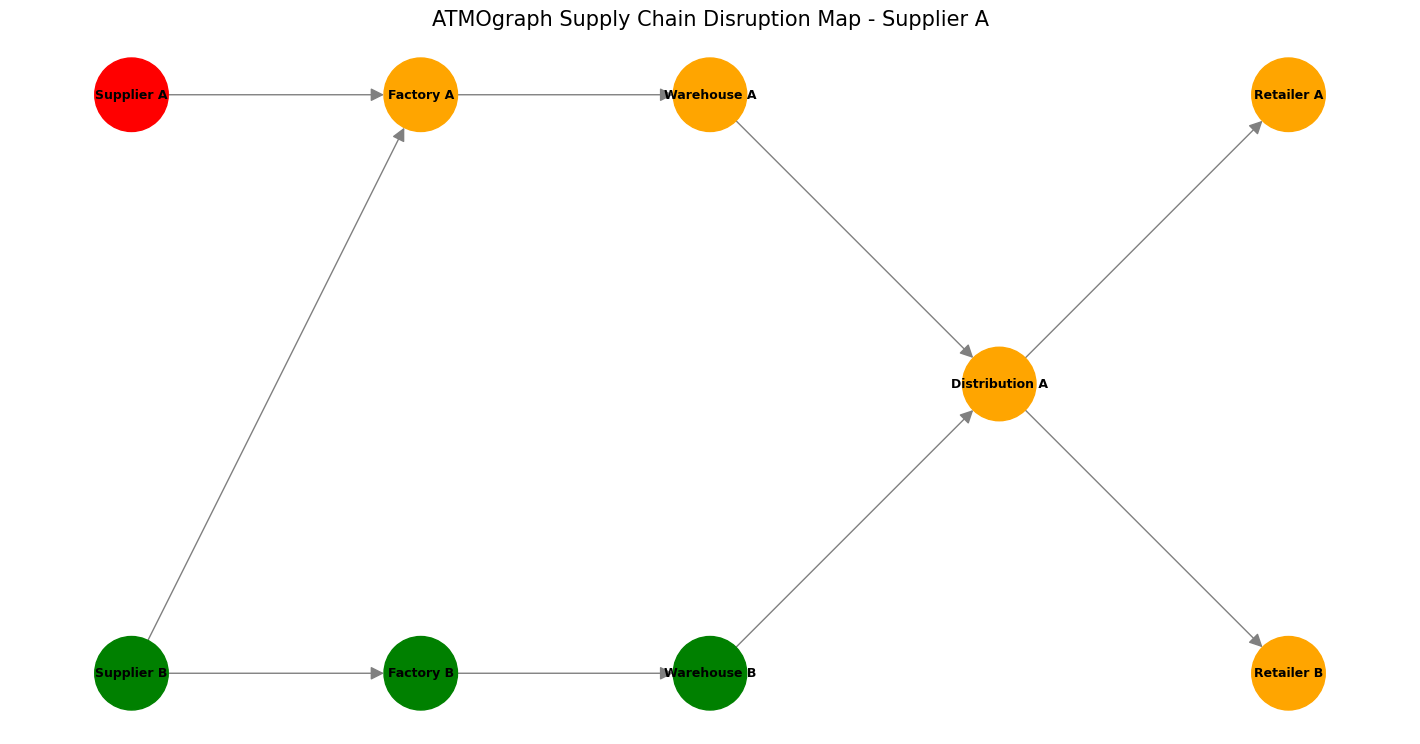

In [55]:
# STEP 82: AtmoGraph Supply Chain Network Visualization

import matplotlib.pyplot as plt
import networkx as nx

def visualize_atmograph_network(supplier):

    affected = nx.descendants(G, supplier)

    node_colors = []

    for node in G.nodes():

        if node == supplier:
            node_colors.append("red")

        elif node in affected:
            node_colors.append("orange")

        else:
            node_colors.append("green")

    positions = {
        "Supplier A": (0, 2),
        "Supplier B": (0, 0),
        "Factory A": (2, 2),
        "Factory B": (2, 0),
        "Warehouse A": (4, 2),
        "Warehouse B": (4, 0),
        "Distribution A": (6, 1),
        "Retailer A": (8, 2),
        "Retailer B": (8, 0)
    }

    plt.figure(figsize=(14, 7))

    nx.draw(
        G,
        pos=positions,
        with_labels=True,
        node_color=node_colors,
        node_size=2800,
        font_size=9,
        font_weight="bold",
        arrows=True,
        arrowsize=20,
        edge_color="gray"
    )

    plt.title(
        f"ATMOgraph Supply Chain Disruption Map - {supplier}",
        fontsize=15
    )

    plt.axis("off")
    plt.show()


visualize_atmograph_network("Supplier A")

In [56]:
# STEP 83: AtmoGraph Dashboard with Network Visualization

import gradio as gr
import matplotlib.pyplot as plt
import networkx as nx

def generate_dashboard(supplier):

    # Run verified combined analysis
    result = atmograph_combined_analysis(
        X_train_safe.iloc[0].to_dict(),
        supplier
    )

    affected = set(result["affected_locations"])

    # Generate network visualization
    positions = {
        "Supplier A": (0, 2),
        "Supplier B": (0, 0),
        "Factory A": (2, 2),
        "Factory B": (2, 0),
        "Warehouse A": (4, 2),
        "Warehouse B": (4, 0),
        "Distribution A": (6, 1),
        "Retailer A": (8, 2),
        "Retailer B": (8, 0)
    }

    colors = []

    for node in G.nodes():
        if node == supplier:
            colors.append("red")
        elif node in affected:
            colors.append("orange")
        else:
            colors.append("green")

    fig, ax = plt.subplots(figsize=(12, 6))

    nx.draw(
        G,
        pos=positions,
        ax=ax,
        with_labels=True,
        node_color=colors,
        node_size=2600,
        font_size=9,
        font_weight="bold",
        arrows=True,
        arrowsize=20,
        edge_color="gray"
    )

    ax.set_title(f"ATMOgraph Network - {supplier}")
    ax.axis("off")

    report = f"""
# ATMOgraph Supply Chain Intelligence

### Delivery Risk
**{result['delivery_risk'] * 100:.2f}%**

### Ripple Impact
**{result['ripple_impact']:.2f}%**

### Disrupted Supplier
**{supplier}**

### Affected Locations
"""

    for location in result["affected_locations"]:
        report += f"\n- {location}"

    return report, fig


with gr.Blocks(title="AtmoGraph AI") as atmograph_visual_app:

    gr.Markdown("# 🌐 ATMOgraph")
    gr.Markdown(
        "### AI-Powered Supply Chain Disruption Prediction"
    )

    supplier = gr.Dropdown(
        choices=["Supplier A", "Supplier B"],
        value="Supplier A",
        label="Select Disrupted Supplier"
    )

    analyze = gr.Button(
        "Run AtmoGraph Analysis",
        variant="primary"
    )

    report = gr.Markdown(label="Analysis Report")

    network_image = gr.Plot(label="Supply Chain Network")

    analyze.click(
        fn=generate_dashboard,
        inputs=supplier,
        outputs=[report, network_image]
    )

atmograph_visual_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a70d6742b5b5e76216.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


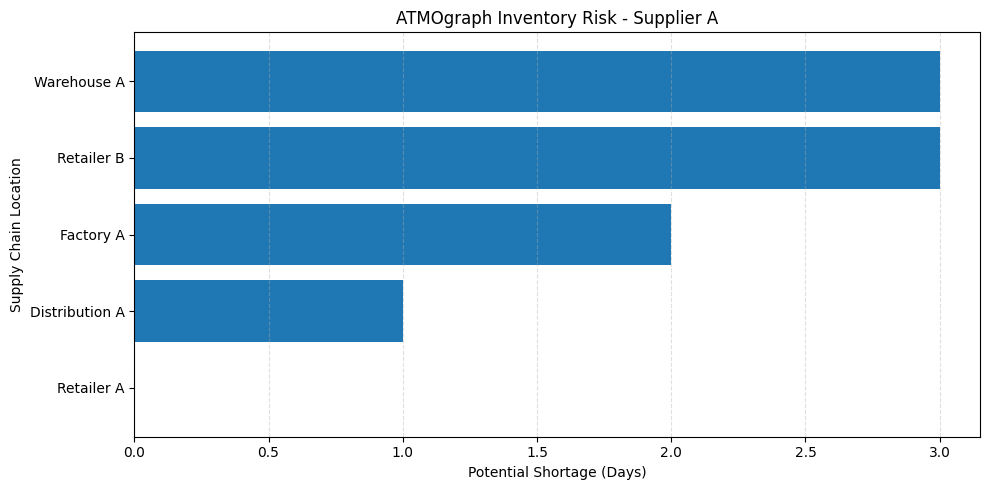

In [57]:
# STEP 84: AtmoGraph Inventory Risk Visualization

import matplotlib.pyplot as plt
import pandas as pd

def generate_inventory_chart(supplier):

    affected = nx.descendants(G, supplier)

    results = []

    for location in sorted(affected):

        buffer_days = inventory_buffer.get(location, 0)
        shortage_days = max(0, 5 - buffer_days)

        results.append({
            "Location": location,
            "Potential Shortage": shortage_days
        })

    chart_df = pd.DataFrame(results)

    chart_df = chart_df.sort_values(
        "Potential Shortage",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.barh(
        chart_df["Location"],
        chart_df["Potential Shortage"]
    )

    ax.set_title(
        f"ATMOgraph Inventory Risk - {supplier}"
    )

    ax.set_xlabel("Potential Shortage (Days)")
    ax.set_ylabel("Supply Chain Location")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()

    return fig


inventory_chart = generate_inventory_chart("Supplier A")

plt.show()

In [58]:
# STEP 85: Complete AtmoGraph Dashboard

import gradio as gr
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

def complete_atmograph_dashboard(supplier):

    # Combined AI analysis
    result = atmograph_combined_analysis(
        X_train_safe.iloc[0].to_dict(),
        supplier
    )

    affected = nx.descendants(G, supplier)

    # Inventory analysis
    inventory_results = []

    for location in sorted(affected):

        buffer_days = inventory_buffer.get(location, 0)
        shortage_days = max(0, 5 - buffer_days)

        if shortage_days >= 3:
            priority = "Critical"
        elif shortage_days >= 2:
            priority = "High"
        elif shortage_days >= 1:
            priority = "Medium"
        else:
            priority = "Low"

        inventory_results.append({
            "Location": location,
            "Inventory Buffer (Days)": buffer_days,
            "Potential Shortage (Days)": shortage_days,
            "Priority": priority
        })

    inventory_df = pd.DataFrame(inventory_results)

    inventory_df = inventory_df.sort_values(
        "Potential Shortage (Days)",
        ascending=False
    ).reset_index(drop=True)

    # Network visualization
    positions = {
        "Supplier A": (0, 2),
        "Supplier B": (0, 0),
        "Factory A": (2, 2),
        "Factory B": (2, 0),
        "Warehouse A": (4, 2),
        "Warehouse B": (4, 0),
        "Distribution A": (6, 1),
        "Retailer A": (8, 2),
        "Retailer B": (8, 0)
    }

    node_colors = [
        "red" if node == supplier
        else "orange" if node in affected
        else "green"
        for node in G.nodes()
    ]

    network_fig, network_ax = plt.subplots(figsize=(12, 6))

    nx.draw(
        G,
        pos=positions,
        ax=network_ax,
        with_labels=True,
        node_color=node_colors,
        node_size=2600,
        font_size=9,
        font_weight="bold",
        arrows=True,
        arrowsize=20,
        edge_color="gray"
    )

    network_ax.set_title("AtmoGraph Supply Chain Network")
    network_ax.axis("off")

    # Inventory chart
    chart_fig, chart_ax = plt.subplots(figsize=(10, 5))

    chart_df = inventory_df.sort_values(
        "Potential Shortage (Days)",
        ascending=True
    )

    chart_ax.barh(
        chart_df["Location"],
        chart_df["Potential Shortage (Days)"]
    )

    chart_ax.set_title("Inventory Shortage Analysis")
    chart_ax.set_xlabel("Potential Shortage (Days)")
    chart_ax.grid(axis="x", linestyle="--", alpha=0.4)

    chart_fig.tight_layout()

    # Analysis report
    critical_count = inventory_df[
        inventory_df["Priority"].isin(["Critical", "High"])
    ].shape[0]

    report = f"""
# 🌐 ATMOgraph Intelligence Dashboard

## Key Performance Indicators

**Delivery Risk:** {result['delivery_risk'] * 100:.2f}%

**Ripple Impact:** {result['ripple_impact']:.2f}%

**Affected Locations:** {len(affected)}

**Critical / High Priority Locations:** {critical_count}

## Disruption Scenario

**Disrupted Supplier:** {supplier}

**Disruption Duration:** 5 assumed days

## Affected Locations

{chr(10).join('- ' + location for location in sorted(affected))}

*Note: Inventory buffers and supplier connections are illustrative
simulation assumptions. The delivery-risk score is a model output,
not a calibrated real-world probability.*
"""

    return report, network_fig, chart_fig, inventory_df


with gr.Blocks(title="AtmoGraph Intelligence Platform") as final_atmograph_app:

    gr.Markdown("# 🌐 ATMOgraph")
    gr.Markdown(
        "### AI-Powered Supply Chain Disruption Prediction & Analysis"
    )

    supplier_input = gr.Dropdown(
        choices=["Supplier A", "Supplier B"],
        value="Supplier A",
        label="Select Disrupted Supplier"
    )

    run_button = gr.Button(
        "Run Complete AtmoGraph Analysis",
        variant="primary"
    )

    report_output = gr.Markdown(label="Intelligence Report")

    gr.Markdown("## Supply Chain Network")
    network_output = gr.Plot()

    gr.Markdown("## Inventory Risk Visualization")
    inventory_chart_output = gr.Plot()

    gr.Markdown("## Intervention Priority Table")
    inventory_table_output = gr.Dataframe(interactive=False)

    run_button.click(
        fn=complete_atmograph_dashboard,
        inputs=supplier_input,
        outputs=[
            report_output,
            network_output,
            inventory_chart_output,
            inventory_table_output
        ]
    )

final_atmograph_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://97556f8289ca6e1f9b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [59]:
# STEP 86: Connect Google Drive and save AtmoGraph

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

project_source = "/content/AtmoGraph"
drive_destination = "/content/drive/MyDrive/AtmoGraph_Project"

os.makedirs(drive_destination, exist_ok=True)

shutil.copytree(
    project_source,
    drive_destination,
    dirs_exist_ok=True
)

print("ATMOgraph BACKUP COMPLETED!")
print("Saved location:", drive_destination)
print("Project folders:", os.listdir(drive_destination))

Mounted at /content/drive
ATMOgraph BACKUP COMPLETED!
Saved location: /content/drive/MyDrive/AtmoGraph_Project
Project folders: ['raw_data', 'processed_data', 'outputs', 'visualizations', 'reports', 'models']


In [60]:
# STEP 88: ATMOgraph Data Leakage Audit

print("=" * 55)
print("       ATMOgraph MODEL VALIDATION AUDIT")
print("=" * 55)

# 1. Check target distribution
print("\n1. TARGET DISTRIBUTION")

print(df["Late_delivery_risk"].value_counts())
print("\nTarget percentages:")
print(
    df["Late_delivery_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# 2. Compare target with actual delivery delay
print("\n2. TARGET VS ACTUAL DELIVERY PERFORMANCE")

df["Audit_Delay_Days"] = (
    df["Days for shipping (real)"] -
    df["Days for shipment (scheduled)"]
)

print(pd.crosstab(
    df["Audit_Delay_Days"] > 0,
    df["Late_delivery_risk"],
    normalize="index"
).round(3))

# 3. Check exact target agreement
actual_late = (
    df["Days for shipping (real)"] >
    df["Days for shipment (scheduled)"]
)

agreement = (
    actual_late == df["Late_delivery_risk"]
).mean() * 100

print("\nTarget agreement with actual delay:", round(agreement, 2), "%")

# 4. Check potentially sensitive columns
print("\n4. POTENTIAL LEAKAGE COLUMNS")

suspicious_columns = [
    "Days for shipping (real)",
    "Delivery Status",
    "Late_delivery_risk",
    "Audit_Delay_Days"
]

for col in suspicious_columns:
    print(col, "->", col in X_train_safe.columns)

# 5. Check available date columns
print("\n5. AVAILABLE DATE COLUMNS")

date_columns = [
    col for col in df.columns
    if "date" in col.lower()
]

print(date_columns)

print("\nAUDIT COMPLETED!")

       ATMOgraph MODEL VALIDATION AUDIT

1. TARGET DISTRIBUTION
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Target percentages:
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64

2. TARGET VS ACTUAL DELIVERY PERFORMANCE
Late_delivery_risk      0      1
Audit_Delay_Days                
False               1.000  0.000
True                0.043  0.957

Target agreement with actual delay: 97.55 %

4. POTENTIAL LEAKAGE COLUMNS
Days for shipping (real) -> False
Delivery Status -> False
Late_delivery_risk -> False
Audit_Delay_Days -> False

5. AVAILABLE DATE COLUMNS
['order date (DateOrders)', 'shipping date (DateOrders)']

AUDIT COMPLETED!


In [61]:
# STEP 89: ATMOgraph Chronological Data Validation

# Parse order dates
df["Order_Date_Parsed"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

# Remove records with invalid dates for this evaluation
temporal_df = df.dropna(
    subset=["Order_Date_Parsed"]
).copy()

# Sort chronologically
temporal_df = temporal_df.sort_values(
    "Order_Date_Parsed"
).reset_index(drop=True)

# Determine chronological 80/20 split
split_index = int(len(temporal_df) * 0.80)

train_temporal = temporal_df.iloc[:split_index].copy()
test_temporal = temporal_df.iloc[split_index:].copy()

print("=" * 50)
print("ATMOgraph CHRONOLOGICAL VALIDATION")
print("=" * 50)

print("\nTotal valid records:", len(temporal_df))

print("\nTRAINING PERIOD")
print("Records:", len(train_temporal))
print("Start:", train_temporal["Order_Date_Parsed"].min())
print("End:", train_temporal["Order_Date_Parsed"].max())

print("\nTESTING PERIOD")
print("Records:", len(test_temporal))
print("Start:", test_temporal["Order_Date_Parsed"].min())
print("End:", test_temporal["Order_Date_Parsed"].max())

print("\nChronological split:",
      round(len(train_temporal) / len(temporal_df) * 100, 2),
      "% training /",
      round(len(test_temporal) / len(temporal_df) * 100, 2),
      "% testing")

print("\nSTEP 89 COMPLETED!")

ATMOgraph CHRONOLOGICAL VALIDATION

Total valid records: 180519

TRAINING PERIOD
Records: 144415
Start: 2015-01-01 00:00:00
End: 2017-04-22 15:17:00

TESTING PERIOD
Records: 36104
Start: 2017-04-22 15:17:00
End: 2018-01-31 23:38:00

Chronological split: 80.0 % training / 20.0 % testing

STEP 89 COMPLETED!


In [62]:
# STEP 90: CREATE CHRONOLOGICAL TRAINING AND TESTING DATA

target = "Late_delivery_risk"

# Use the 80% boundary timestamp from the sorted dataset
cutoff_date = temporal_df.iloc[split_index]["Order_Date_Parsed"]

# Keep all records with the same timestamp in the same split
train_temporal = temporal_df[
    temporal_df["Order_Date_Parsed"] < cutoff_date
].copy()

test_temporal = temporal_df[
    temporal_df["Order_Date_Parsed"] >= cutoff_date
].copy()

# Select only approved prediction features and the target
temporal_train = train_temporal[safe_features + [target]].copy()
temporal_test = test_temporal[safe_features + [target]].copy()

print("=" * 50)
print("ATMOgraph CHRONOLOGICAL DATASETS")
print("=" * 50)

print("\nCutoff date:", cutoff_date)
print("\nTraining records:", len(temporal_train))
print("Testing records:", len(temporal_test))

print("\nTraining period:")
print(train_temporal["Order_Date_Parsed"].min(),
      "to",
      train_temporal["Order_Date_Parsed"].max())

print("\nTesting period:")
print(test_temporal["Order_Date_Parsed"].min(),
      "to",
      test_temporal["Order_Date_Parsed"].max())

print("\nTraining target distribution:")
print(temporal_train[target].value_counts())

print("\nTesting target distribution:")
print(temporal_test[target].value_counts())

print("\nSTEP 90 COMPLETED!")

ATMOgraph CHRONOLOGICAL DATASETS

Cutoff date: 2017-04-22 15:17:00

Training records: 144412
Testing records: 36107

Training period:
2015-01-01 00:00:00 to 2017-04-22 14:56:00

Testing period:
2017-04-22 15:17:00 to 2018-01-31 23:38:00

Training target distribution:
Late_delivery_risk
1    79241
0    65171
Name: count, dtype: int64

Testing target distribution:
Late_delivery_risk
1    19736
0    16371
Name: count, dtype: int64

STEP 90 COMPLETED!


In [63]:
# STEP 91: TRAIN-ONLY PREPROCESSING

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate features and target
X_train_temporal = temporal_train.drop(columns=[target])
y_train_temporal = temporal_train[target].astype(int)

X_test_temporal = temporal_test.drop(columns=[target])
y_test_temporal = temporal_test[target].astype(int)

# Identify column types using training data only
cat_cols_temporal = X_train_temporal.select_dtypes(
    include=["object"]
).columns.tolist()

num_cols_temporal = X_train_temporal.select_dtypes(
    include=["number"]
).columns.tolist()

# Handle missing values and encode categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

temporal_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, cat_cols_temporal),
    ("numeric", numeric_pipeline, num_cols_temporal)
])

# Fit ONLY on training data
X_train_temporal_encoded = temporal_preprocessor.fit_transform(
    X_train_temporal
)

# Transform testing data without fitting again
X_test_temporal_encoded = temporal_preprocessor.transform(
    X_test_temporal
)

print("=" * 50)
print("ATMOgraph TEMPORAL PREPROCESSING")
print("=" * 50)

print("Training shape:", X_train_temporal_encoded.shape)
print("Testing shape:", X_test_temporal_encoded.shape)
print("Categorical features:", len(cat_cols_temporal))
print("Numeric features:", len(num_cols_temporal))
print("Same encoded feature count:",
      X_train_temporal_encoded.shape[1] == X_test_temporal_encoded.shape[1])

print("\nSTEP 91 COMPLETED!")

ATMOgraph TEMPORAL PREPROCESSING
Training shape: (144412, 233)
Testing shape: (36107, 233)
Categorical features: 7
Numeric features: 6
Same encoded feature count: True

STEP 91 COMPLETED!


In [64]:
# STEP 92: TRAIN ATMOgraph TEMPORAL MODEL

from sklearn.ensemble import RandomForestClassifier

temporal_rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

temporal_rf_model.fit(
    X_train_temporal_encoded,
    y_train_temporal
)

print("=" * 50)
print("ATMOgraph TEMPORAL MODEL TRAINING")
print("=" * 50)

print("Model:", "Random Forest Classifier")
print("Training records:", X_train_temporal_encoded.shape[0])
print("Encoded features:", X_train_temporal_encoded.shape[1])
print("Model training completed successfully!")

print("\nSTEP 92 COMPLETED!")

ATMOgraph TEMPORAL MODEL TRAINING
Model: Random Forest Classifier
Training records: 144412
Encoded features: 233
Model training completed successfully!

STEP 92 COMPLETED!


In [65]:
# STEP 93: CHRONOLOGICAL MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the future-period test dataset
y_temporal_pred = temporal_rf_model.predict(
    X_test_temporal_encoded
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_temporal, y_temporal_pred)
precision = precision_score(y_test_temporal, y_temporal_pred, zero_division=0)
recall = recall_score(y_test_temporal, y_temporal_pred, zero_division=0)
f1 = f1_score(y_test_temporal, y_temporal_pred, zero_division=0)

print("=" * 55)
print("ATMOgraph CHRONOLOGICAL MODEL EVALUATION")
print("=" * 55)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_temporal,
    y_temporal_pred,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test_temporal, y_temporal_pred))

print("\nSTEP 93 COMPLETED!")

ATMOgraph CHRONOLOGICAL MODEL EVALUATION
Accuracy : 69.17%
Precision: 83.70%
Recall   : 54.15%
F1 Score : 65.76%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.61      0.87      0.72     16371
           1       0.84      0.54      0.66     19736

    accuracy                           0.69     36107
   macro avg       0.72      0.71      0.69     36107
weighted avg       0.74      0.69      0.69     36107


CONFUSION MATRIX
[[14290  2081]
 [ 9049 10687]]

STEP 93 COMPLETED!


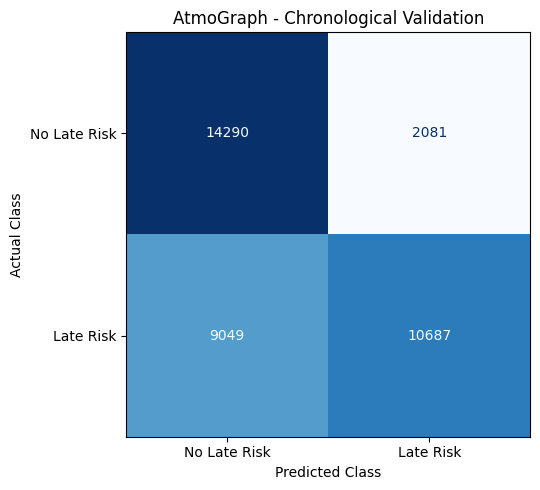

Confusion matrix visualization saved successfully!
STEP 94 COMPLETED!


In [66]:
# STEP 94: CHRONOLOGICAL CONFUSION MATRIX

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test_temporal, y_temporal_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Late Risk", "Late Risk"]
)

fig, ax = plt.subplots(figsize=(7, 5))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("AtmoGraph - Chronological Validation")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "/content/AtmoGraph/outputs/AtmoGraph_Chronological_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix visualization saved successfully!")
print("STEP 94 COMPLETED!")

In [67]:
# STEP 95: ANALYZE MISSED LATE-RISK CASES

# Combine test features, actual labels and predictions
error_analysis = X_test_temporal.copy()

error_analysis["Actual"] = y_test_temporal.values
error_analysis["Predicted"] = y_temporal_pred

# False negatives: actual late risk, but predicted as no late risk
missed_late_cases = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
].copy()

print("=" * 55)
print("ATMOgraph - MISSED LATE-RISK ANALYSIS")
print("=" * 55)

print("Total testing records:", len(error_analysis))
print("Missed late-risk cases:", len(missed_late_cases))
print(
    "Missed late-risk percentage:",
    round(len(missed_late_cases) / len(error_analysis) * 100, 2),
    "%"
)

# Examine patterns by shipping mode
if "Shipping Mode" in missed_late_cases.columns:
    print("\nMISSED CASES BY SHIPPING MODE")
    print(missed_late_cases["Shipping Mode"].value_counts())

# Examine patterns by market
if "Market" in missed_late_cases.columns:
    print("\nMISSED CASES BY MARKET")
    print(missed_late_cases["Market"].value_counts())

# Compare feature averages
numeric_columns = missed_late_cases.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nNUMERIC FEATURE AVERAGES")
print(
    missed_late_cases[numeric_columns]
    .drop(columns=["Actual", "Predicted"], errors="ignore")
    .mean()
    .round(2)
)

print("\nSTEP 95 COMPLETED!")

ATMOgraph - MISSED LATE-RISK ANALYSIS
Total testing records: 36107
Missed late-risk cases: 9049
Missed late-risk percentage: 25.06 %

MISSED CASES BY SHIPPING MODE
Shipping Mode
Standard Class    8138
Same Day           911
Name: count, dtype: int64

MISSED CASES BY MARKET
Market
Europe          5215
LATAM           2393
Pacific Asia    1441
Name: count, dtype: int64

NUMERIC FEATURE AVERAGES
Order Item Quantity                1.82
Order Item Product Price         179.43
Order Item Discount               23.23
Order Item Discount Rate           0.10
Order Item Total                 205.64
Days for shipment (scheduled)      3.60
dtype: float64

STEP 95 COMPLETED!


In [68]:
# STEP 96: GROUP-WISE LATE-RISK RECALL ANALYSIS

# Include actual labels and predictions with test features
group_analysis = X_test_temporal.copy()
group_analysis["Actual"] = y_test_temporal.values
group_analysis["Predicted"] = y_temporal_pred

# Calculate recall by shipping mode
shipping_analysis = (
    group_analysis[group_analysis["Actual"] == 1]
    .groupby("Shipping Mode")
    .agg(
        Actual_Late_Cases=("Actual", "count"),
        Correctly_Detected=("Predicted", "sum")
    )
)

shipping_analysis["Missed_Cases"] = (
    shipping_analysis["Actual_Late_Cases"] -
    shipping_analysis["Correctly_Detected"]
)

shipping_analysis["Recall_Percent"] = (
    shipping_analysis["Correctly_Detected"] /
    shipping_analysis["Actual_Late_Cases"] * 100
).round(2)

print("=" * 55)
print("LATE-RISK RECALL BY SHIPPING MODE")
print("=" * 55)
print(shipping_analysis.sort_values("Recall_Percent"))

# Calculate recall by market
market_analysis = (
    group_analysis[group_analysis["Actual"] == 1]
    .groupby("Market")
    .agg(
        Actual_Late_Cases=("Actual", "count"),
        Correctly_Detected=("Predicted", "sum")
    )
)

market_analysis["Missed_Cases"] = (
    market_analysis["Actual_Late_Cases"] -
    market_analysis["Correctly_Detected"]
)

market_analysis["Recall_Percent"] = (
    market_analysis["Correctly_Detected"] /
    market_analysis["Actual_Late_Cases"] * 100
).round(2)

print("\n" + "=" * 55)
print("LATE-RISK RECALL BY MARKET")
print("=" * 55)
print(market_analysis.sort_values("Recall_Percent"))

print("\nSTEP 96 COMPLETED!")


LATE-RISK RECALL BY SHIPPING MODE
                Actual_Late_Cases  Correctly_Detected  Missed_Cases  \
Shipping Mode                                                         
Standard Class               8146                   8          8138   
Same Day                      987                  76           911   
First Class                  5243                5243             0   
Second Class                 5360                5360             0   

                Recall_Percent  
Shipping Mode                   
Standard Class             0.1  
Same Day                   7.7  
First Class              100.0  
Second Class             100.0  

LATE-RISK RECALL BY MARKET
              Actual_Late_Cases  Correctly_Detected  Missed_Cases  \
Market                                                              
LATAM                      5155                2762          2393   
Pacific Asia               3119                1678          1441   
Europe                    11462      

In [69]:
# STEP 97: SHIPPING MODE AND TARGET RELATIONSHIP

shipping_target_analysis = pd.crosstab(
    X_train_temporal["Shipping Mode"],
    y_train_temporal,
    normalize="index"
) * 100

shipping_target_analysis.columns = [
    "No_Late_Risk_Percent",
    "Late_Risk_Percent"
]

print("=" * 55)
print("TRAINING DATA: SHIPPING MODE VS LATE-RISK")
print("=" * 55)

print(shipping_target_analysis.round(2))

print("\nTESTING DATA: SHIPPING MODE VS LATE-RISK")

testing_shipping_analysis = pd.crosstab(
    X_test_temporal["Shipping Mode"],
    y_test_temporal,
    normalize="index"
) * 100

testing_shipping_analysis.columns = [
    "No_Late_Risk_Percent",
    "Late_Risk_Percent"
]

print(testing_shipping_analysis.round(2))

print("\nSTEP 97 COMPLETED!")

TRAINING DATA: SHIPPING MODE VS LATE-RISK
                No_Late_Risk_Percent  Late_Risk_Percent
Shipping Mode                                          
First Class                     4.46              95.54
Same Day                       55.43              44.57
Second Class                   23.24              76.76
Standard Class                 61.86              38.14

TESTING DATA: SHIPPING MODE VS LATE-RISK
                No_Late_Risk_Percent  Late_Risk_Percent
Shipping Mode                                          
First Class                     5.53              94.47
Same Day                       49.62              50.38
Second Class                   23.87              76.13
Standard Class                 62.21              37.79

STEP 97 COMPLETED!


In [70]:
# STEP 98: PREDICTION PROBABILITY ANALYSIS

# Get probability of the late-risk class
temporal_probabilities = temporal_rf_model.predict_proba(
    X_test_temporal_encoded
)[:, 1]

probability_analysis = X_test_temporal.copy()

probability_analysis["Actual"] = y_test_temporal.values
probability_analysis["Predicted_Probability"] = temporal_probabilities

print("=" * 55)
print("ATMOgraph PREDICTION PROBABILITY ANALYSIS")
print("=" * 55)

print("\nProbability distribution for actual late-risk cases:")
print(
    probability_analysis[
        probability_analysis["Actual"] == 1
    ]["Predicted_Probability"].describe().round(3)
)

print("\nProbability distribution for actual non-late-risk cases:")
print(
    probability_analysis[
        probability_analysis["Actual"] == 0
    ]["Predicted_Probability"].describe().round(3)
)

print("\nProbability distribution by shipping mode:")
print(
    probability_analysis.groupby("Shipping Mode")[
        "Predicted_Probability"
    ].agg(["count", "mean", "median"]).round(3)
)

print("\nSTEP 98 COMPLETED!")

ATMOgraph PREDICTION PROBABILITY ANALYSIS

Probability distribution for actual late-risk cases:
count    19736.000
mean         0.605
std          0.241
min          0.271
25%          0.359
50%          0.662
75%          0.816
max          0.959
Name: Predicted_Probability, dtype: float64

Probability distribution for actual non-late-risk cases:
count    16371.000
mean         0.399
std          0.130
min          0.269
25%          0.340
50%          0.358
75%          0.372
max          0.882
Name: Predicted_Probability, dtype: float64

Probability distribution by shipping mode:
                count   mean  median
Shipping Mode                       
First Class      5550  0.904   0.931
Same Day         1959  0.446   0.449
Second Class     7041  0.724   0.739
Standard Class  21557  0.348   0.356

STEP 98 COMPLETED!


In [71]:
# STEP 99: THRESHOLD OPTIMIZATION

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

threshold_results = []

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

for threshold in thresholds:

    predictions = (
        temporal_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_temporal, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_temporal, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_temporal, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("=" * 65)
print("ATMOgraph - THRESHOLD COMPARISON")
print("=" * 65)

print(threshold_df.round(3).to_string(index=False))

print("\nSTEP 99 COMPLETED!")

ATMOgraph - THRESHOLD COMPARISON
 Threshold  Precision  Recall  F1_Score
      0.30      0.552   0.987     0.708
      0.35      0.602   0.863     0.709
      0.40      0.802   0.584     0.675
      0.45      0.820   0.565     0.669
      0.50      0.837   0.541     0.658
      0.55      0.841   0.538     0.656
      0.60      0.842   0.537     0.656
      0.65      0.850   0.517     0.643
      0.70      0.872   0.471     0.612

STEP 99 COMPLETED!


In [72]:
# STEP 100: EVALUATE SELECTED CANDIDATE THRESHOLD

selected_threshold = 0.35

selected_predictions = (
    temporal_probabilities >= selected_threshold
).astype(int)

selected_cm = confusion_matrix(
    y_test_temporal,
    selected_predictions
)

tn, fp, fn, tp = selected_cm.ravel()

print("=" * 55)
print("ATMOgraph - THRESHOLD 0.35 EVALUATION")
print("=" * 55)

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print("\nPrecision:",
      round(precision_score(y_test_temporal, selected_predictions) * 100, 2), "%")

print("Recall:",
      round(recall_score(y_test_temporal, selected_predictions) * 100, 2), "%")

print("F1 Score:",
      round(f1_score(y_test_temporal, selected_predictions) * 100, 2), "%")

print("\nSTEP 100 COMPLETED!")


ATMOgraph - THRESHOLD 0.35 EVALUATION
True Negatives : 5097
False Positives: 11274
False Negatives: 2700
True Positives : 17036

Precision: 60.18 %
Recall: 86.32 %
F1 Score: 70.92 %

STEP 100 COMPLETED!


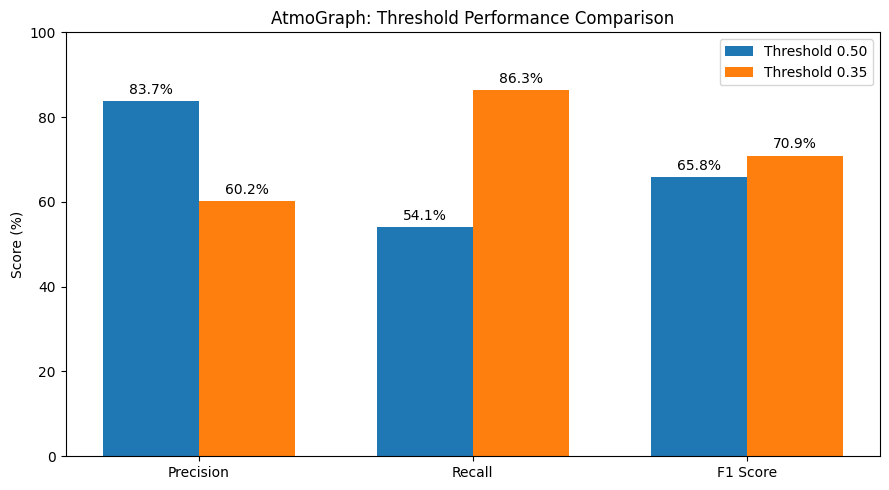

Threshold comparison chart saved!
STEP 101 COMPLETED!


In [73]:
# STEP 101: THRESHOLD PERFORMANCE COMPARISON

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1 Score"]

default_values = [83.70, 54.15, 65.76]
selected_values = [60.18, 86.32, 70.92]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - width/2, default_values, width, label="Threshold 0.50")
ax.bar(x + width/2, selected_values, width, label="Threshold 0.35")

ax.set_ylabel("Score (%)")
ax.set_title("AtmoGraph: Threshold Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 100)
ax.legend()

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()

plt.savefig(
    "/content/AtmoGraph/outputs/AtmoGraph_Threshold_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Threshold comparison chart saved!")
print("STEP 101 COMPLETED!")


In [74]:
# STEP 102: CREATE TRAINING AND VALIDATION SETS

from sklearn.model_selection import train_test_split

# Split the existing chronological training period
X_train_final, X_validation = train_test_split(
    X_train_temporal,
    test_size=0.20,
    random_state=42,
    stratify=y_train_temporal
)

y_train_final = y_train_temporal.loc[X_train_final.index]
y_validation = y_train_temporal.loc[X_validation.index]

print("=" * 55)
print("ATMOgraph TRAINING AND VALIDATION SPLIT")
print("=" * 55)

print("Training records:", len(X_train_final))
print("Validation records:", len(X_validation))
print("Final testing records:", len(X_test_temporal))

print("\nTraining target distribution:")
print(y_train_final.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_validation.value_counts(normalize=True).round(3))

print("\nFinal testing period remains untouched.")

print("\nSTEP 102 COMPLETED!")


ATMOgraph TRAINING AND VALIDATION SPLIT
Training records: 115529
Validation records: 28883
Final testing records: 36107

Training target distribution:
Late_delivery_risk
1    0.549
0    0.451
Name: proportion, dtype: float64

Validation target distribution:
Late_delivery_risk
1    0.549
0    0.451
Name: proportion, dtype: float64

Final testing period remains untouched.

STEP 102 COMPLETED!


In [75]:
# STEP 103: PREPROCESS TRAINING, VALIDATION AND TEST DATA

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify feature types from training data only
cat_cols_final = X_train_final.select_dtypes(
    include=["object"]
).columns.tolist()

num_cols_final = X_train_final.select_dtypes(
    include=["number"]
).columns.tolist()

# Build preprocessing pipelines
categorical_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

final_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline_final, cat_cols_final),
    ("numeric", numeric_pipeline_final, num_cols_final)
])

# Fit only on training subset
X_train_final_encoded = final_preprocessor.fit_transform(
    X_train_final
)

# Transform validation and final test data
X_validation_encoded = final_preprocessor.transform(
    X_validation
)

X_test_final_encoded = final_preprocessor.transform(
    X_test_temporal
)

print("=" * 55)
print("ATMOgraph FINAL PREPROCESSING")
print("=" * 55)

print("Training shape:", X_train_final_encoded.shape)
print("Validation shape:", X_validation_encoded.shape)
print("Testing shape:", X_test_final_encoded.shape)

print(
    "\nMatching feature dimensions:",
    X_train_final_encoded.shape[1]
    == X_validation_encoded.shape[1]
    == X_test_final_encoded.shape[1]
)

print("\nSTEP 103 COMPLETED!")

ATMOgraph FINAL PREPROCESSING
Training shape: (115529, 233)
Validation shape: (28883, 233)
Testing shape: (36107, 233)

Matching feature dimensions: True

STEP 103 COMPLETED!


In [76]:
# STEP 104: TRAIN FINAL ATMOgraph MODEL

from sklearn.ensemble import RandomForestClassifier

final_rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

final_rf_model.fit(
    X_train_final_encoded,
    y_train_final
)

print("=" * 55)
print("ATMOgraph FINAL CANDIDATE MODEL")
print("=" * 55)

print("Algorithm: Random Forest Classifier")
print("Training records:", X_train_final_encoded.shape[0])
print("Features:", X_train_final_encoded.shape[1])
print("Validation records:", X_validation_encoded.shape[0])
print("Final testing records:", X_test_final_encoded.shape[0])

print("\nModel training completed successfully!")
print("STEP 104 COMPLETED!")

ATMOgraph FINAL CANDIDATE MODEL
Algorithm: Random Forest Classifier
Training records: 115529
Features: 233
Validation records: 28883
Final testing records: 36107

Model training completed successfully!
STEP 104 COMPLETED!


In [77]:
# STEP 105: Generate validation probabilities

validation_probabilities = final_rf_model.predict_proba(
    X_validation_encoded
)[:, 1]

print("VALIDATION PROBABILITY GENERATION")
print("=================================")
print("Validation records:", len(validation_probabilities))
print("Minimum probability:", round(validation_probabilities.min(), 4))
print("Maximum probability:", round(validation_probabilities.max(), 4))
print("Average probability:", round(validation_probabilities.mean(), 4))

print("\nSTEP 105 COMPLETED!")

VALIDATION PROBABILITY GENERATION
Validation records: 28883
Minimum probability: 0.2046
Maximum probability: 0.955
Average probability: 0.5112

STEP 105 COMPLETED!


In [78]:
# STEP 106: Compare prediction thresholds using validation data

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50,
              0.55, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:
    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_validation, validation_predictions
        ),
        "Recall": recall_score(
            y_validation, validation_predictions
        ),
        "F1 Score": f1_score(
            y_validation, validation_predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("ATMOgraph VALIDATION THRESHOLD COMPARISON")
print("=========================================")

display(
    threshold_df.round(4).sort_values(
        by="F1 Score", ascending=False
    )
)

print("\nSTEP 106 COMPLETED!")


ATMOgraph VALIDATION THRESHOLD COMPARISON


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [79]:
# STEP 106: Compare validation thresholds

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50,
              0.55, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:
    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_validation, validation_predictions
        ),
        "Recall": recall_score(
            y_validation, validation_predictions
        ),
        "F1 Score": f1_score(
            y_validation, validation_predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("ATMOgraph VALIDATION THRESHOLD COMPARISON")
print("=========================================")
print(
    threshold_df.round(4).sort_values(
        by="F1 Score", ascending=False
    ).to_string(index=False)
)

print("\nSTEP 106 COMPLETED!")



ATMOgraph VALIDATION THRESHOLD COMPARISON
 Threshold  Precision  Recall  F1 Score
      0.35     0.6037  0.8802    0.7162
      0.30     0.5529  0.9937    0.7105
      0.40     0.7967  0.5915    0.6789
      0.45     0.8296  0.5654    0.6725
      0.50     0.8445  0.5463    0.6634
      0.55     0.8459  0.5417    0.6604
      0.60     0.8462  0.5401    0.6593
      0.65     0.8603  0.5206    0.6487
      0.70     0.8808  0.4695    0.6125

STEP 106 COMPLETED!


In [80]:
# STEP 107: Lock the selected validation threshold

FINAL_THRESHOLD = 0.35

print("ATMOgraph FINAL THRESHOLD CONFIGURATION")
print("=======================================")
print("Selected threshold:", FINAL_THRESHOLD)
print("Selection basis: Validation F1 Score")
print("Validation Precision: 60.37%")
print("Validation Recall: 88.02%")
print("Validation F1 Score: 71.62%")

print("\nThreshold locked successfully!")
print("STEP 107 COMPLETED!")

ATMOgraph FINAL THRESHOLD CONFIGURATION
Selected threshold: 0.35
Selection basis: Validation F1 Score
Validation Precision: 60.37%
Validation Recall: 88.02%
Validation F1 Score: 71.62%

Threshold locked successfully!
STEP 107 COMPLETED!


In [81]:
# STEP 108: Predict on the untouched final test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Generate final test probabilities
final_test_probabilities = final_rf_model.predict_proba(
    X_test_final_encoded
)[:, 1]

# Apply the locked validation threshold
final_test_predictions = (
    final_test_probabilities >= FINAL_THRESHOLD
).astype(int)

print("ATMOgraph FINAL TEST PREDICTIONS")
print("================================")
print("Test records:", len(y_test_temporal))
print("Locked threshold:", FINAL_THRESHOLD)
print("Predictions generated:", len(final_test_predictions))

print("\nSTEP 108 COMPLETED!")

ATMOgraph FINAL TEST PREDICTIONS
Test records: 36107
Locked threshold: 0.35
Predictions generated: 36107

STEP 108 COMPLETED!


In [82]:
# STEP 109: ATMOgraph final model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

final_accuracy = accuracy_score(
    y_test_temporal, final_test_predictions
)

final_precision = precision_score(
    y_test_temporal, final_test_predictions
)

final_recall = recall_score(
    y_test_temporal, final_test_predictions
)

final_f1 = f1_score(
    y_test_temporal, final_test_predictions
)

print("=" * 55)
print("       ATMOgraph FINAL MODEL EVALUATION")
print("=" * 55)

print(f"Accuracy  : {final_accuracy * 100:.2f}%")
print(f"Precision : {final_precision * 100:.2f}%")
print(f"Recall    : {final_recall * 100:.2f}%")
print(f"F1 Score  : {final_f1 * 100:.2f}%")

print("\nCONFUSION MATRIX")
print(confusion_matrix(
    y_test_temporal, final_test_predictions
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_temporal,
    final_test_predictions,
    target_names=["No Late Delivery", "Late Delivery"]
))

print("STEP 109 COMPLETED!")

       ATMOgraph FINAL MODEL EVALUATION
Accuracy  : 60.94%
Precision : 59.73%
Recall    : 87.63%
F1 Score  : 71.04%

CONFUSION MATRIX
[[ 4711 11660]
 [ 2442 17294]]

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

No Late Delivery       0.66      0.29      0.40     16371
   Late Delivery       0.60      0.88      0.71     19736

        accuracy                           0.61     36107
       macro avg       0.63      0.58      0.56     36107
    weighted avg       0.63      0.61      0.57     36107

STEP 109 COMPLETED!


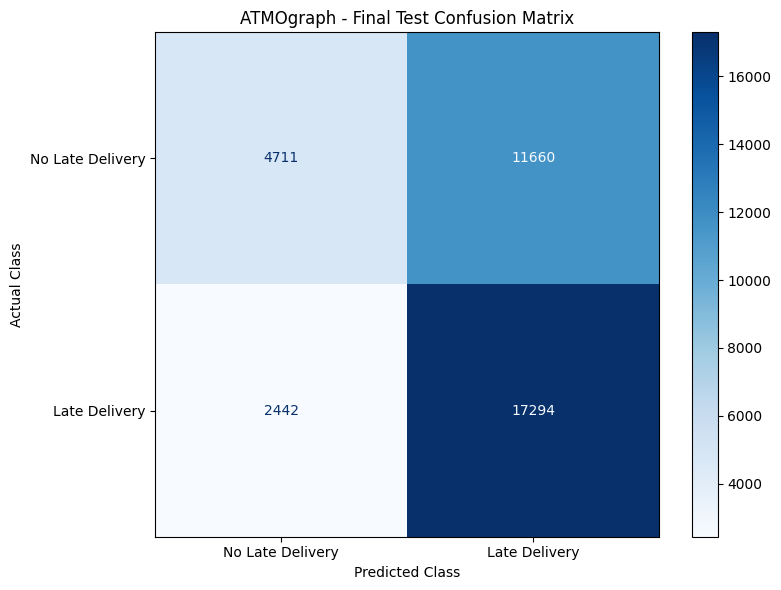

Final confusion matrix saved successfully!
STEP 110 COMPLETED!


In [83]:
# STEP 110: Final confusion matrix visualization

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_temporal,
    final_test_predictions
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Late Delivery", "Late Delivery"]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("ATMOgraph - Final Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "/content/AtmoGraph/outputs/AtmoGraph_Final_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final confusion matrix saved successfully!")
print("STEP 110 COMPLETED!")

In [84]:
# STEP 111: Save final evaluation metrics

import os
import pandas as pd

metrics = {
    "Metric": [
        "Algorithm",
        "Training Records",
        "Validation Records",
        "Final Test Records",
        "Decision Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Value": [
        "Random Forest Classifier",
        len(y_train_final),
        len(y_validation),
        len(y_test_temporal),
        FINAL_THRESHOLD,
        round(final_accuracy * 100, 2),
        round(final_precision * 100, 2),
        round(final_recall * 100, 2),
        round(final_f1 * 100, 2)
    ]
}

metrics_df = pd.DataFrame(metrics)

os.makedirs("/content/AtmoGraph/reports", exist_ok=True)

metrics_path = (
    "/content/AtmoGraph/reports/"
    "AtmoGraph_Final_Evaluation_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

print("ATMOgraph FINAL METRICS")
print("=======================")
print(metrics_df.to_string(index=False))
print("\nSaved to:", metrics_path)
print("\nSTEP 111 COMPLETED!")

ATMOgraph FINAL METRICS
            Metric                    Value
         Algorithm Random Forest Classifier
  Training Records                   115529
Validation Records                    28883
Final Test Records                    36107
Decision Threshold                     0.35
          Accuracy                    60.94
         Precision                    59.73
            Recall                    87.63
          F1 Score                    71.04

Saved to: /content/AtmoGraph/reports/AtmoGraph_Final_Evaluation_Metrics.csv

STEP 111 COMPLETED!


In [87]:
# STEP 111: Save final evaluation metrics

import os
import pandas as pd

metrics = {
    "Metric": [
        "Algorithm",
        "Training Records",
        "Validation Records",
        "Final Test Records",
        "Decision Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Value": [
        "Random Forest Classifier",
        len(y_train_final),
        len(y_validation),
        len(y_test_temporal),
        FINAL_THRESHOLD,
        round(final_accuracy * 100, 2),
        round(final_precision * 100, 2),
        round(final_recall * 100, 2),
        round(final_f1 * 100, 2)
    ]
}

metrics_df = pd.DataFrame(metrics)

os.makedirs("/content/AtmoGraph/reports", exist_ok=True)

metrics_path = (
    "/content/AtmoGraph/reports/"
    "AtmoGraph_Final_Evaluation_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

print("ATMOgraph FINAL METRICS")
print("=======================")
print(metrics_df.to_string(index=False))
print("\nSaved to:", metrics_path)
print("\nSTEP 111 COMPLETED!")

ATMOgraph FINAL METRICS
            Metric                    Value
         Algorithm Random Forest Classifier
  Training Records                   115529
Validation Records                    28883
Final Test Records                    36107
Decision Threshold                     0.35
          Accuracy                    60.94
         Precision                    59.73
            Recall                    87.63
          F1 Score                    71.04

Saved to: /content/AtmoGraph/reports/AtmoGraph_Final_Evaluation_Metrics.csv

STEP 111 COMPLETED!


In [88]:
# STEP 112: Create ATMOgraph model evaluation report

import os
from datetime import datetime

report = """
============================================================
                  ATMOgraph
       AI-POWERED SUPPLY CHAIN DISRUPTION PREDICTOR
              FINAL MODEL EVALUATION REPORT
============================================================

1. PROJECT OVERVIEW

AtmoGraph is an AI-powered prototype designed to analyse
delivery risk and simulate supply-chain disruption impacts.

The system combines machine learning-based delivery risk
classification with a simulated supply-chain dependency
network and inventory shortage analysis.

2. DATASET

Dataset: DataCo Supply Chain Dataset
Total records: 180,519
Target variable: Late_delivery_risk

The dataset contains historical order, product, customer,
market and shipping information.

3. MODEL CONFIGURATION

Algorithm: Random Forest Classifier
Training records: 115,529
Validation records: 28,883
Final testing records: 36,107
Encoded features: 233
Selected decision threshold: 0.35

The threshold was selected using validation F1 score.
The final test set was kept separate during threshold
selection.

4. FINAL TEST PERFORMANCE

Accuracy: 60.94%
Precision: 59.73%
Recall: 87.63%
F1 Score: 71.04%

5. CONFUSION MATRIX

True Negatives: 4,711
False Positives: 11,660
False Negatives: 2,442
True Positives: 17,294

6. RESULTS INTERPRETATION

The model identified 87.63% of actual late-delivery
cases in the final test set.

Its precision was 59.73%, indicating that a substantial
number of orders classified as high risk were not actually
late.

The model therefore prioritises identifying potential
late deliveries, while producing a relatively high number
of false alerts.

7. PROJECT LIMITATIONS

- The dataset contains historical order and shipping
  transactions, not verified multi-tier supplier records.
- The supply-chain dependency graph is a simulated
  prototype network.
- Inventory buffers and disruption durations are
  illustrative assumptions.
- Model predictions are estimates, not guaranteed outcomes.
- The chronological test results should be interpreted
  alongside the limitations of the available features
  and target definition.

8. FUTURE IMPROVEMENTS

- Integrate verified supplier dependency data.
- Use real inventory and lead-time information.
- Improve false-positive reduction.
- Evaluate probability calibration.
- Test with additional real-world supply-chain datasets.
- Deploy the system through an interactive application.

9. CONCLUSION

AtmoGraph demonstrates an integrated prototype combining
machine learning-based delivery risk classification,
supply-chain ripple-effect simulation and inventory
shortage prioritisation.

The final Random Forest model achieved an F1 score of
71.04% and recall of 87.63% on the chronological test set.

Further validation with real supplier and inventory data
is required before operational deployment.

============================================================
                    END OF REPORT
============================================================
"""

report_path = (
    "/content/AtmoGraph/reports/"
    "AtmoGraph_Final_Model_Evaluation_Report.txt"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print("ATMOgraph FINAL REPORT CREATED!")
print("================================")
print("File:", report_path)
print("Report size:", os.path.getsize(report_path), "bytes")
print("\nSTEP 112 COMPLETED!")

ATMOgraph FINAL REPORT CREATED!
File: /content/AtmoGraph/reports/AtmoGraph_Final_Model_Evaluation_Report.txt
Report size: 2991 bytes

STEP 112 COMPLETED!


In [89]:
# STEP 113: Save the final trained model bundle

import os
import joblib

os.makedirs("/content/AtmoGraph/models", exist_ok=True)

final_model_bundle = {
    "model": final_rf_model,
    "preprocessor": final_preprocessor,
    "threshold": FINAL_THRESHOLD,
    "features": safe_features,
    "algorithm": "Random Forest Classifier",
    "test_accuracy": final_accuracy,
    "test_precision": final_precision,
    "test_recall": final_recall,
    "test_f1_score": final_f1
}

model_path = (
    "/content/AtmoGraph/models/"
    "AtmoGraph_Final_Model_Bundle.pkl"
)

joblib.dump(final_model_bundle, model_path)

print("ATMOgraph FINAL MODEL SAVED!")
print("================================")
print("Model:", model_path)
print("Algorithm:", final_model_bundle["algorithm"])
print("Threshold:", FINAL_THRESHOLD)
print("Model features:", len(safe_features))
print("Final test F1:", round(final_f1 * 100, 2), "%")

print("\nSTEP 113 COMPLETED!")

ATMOgraph FINAL MODEL SAVED!
Model: /content/AtmoGraph/models/AtmoGraph_Final_Model_Bundle.pkl
Algorithm: Random Forest Classifier
Threshold: 0.35
Model features: 13
Final test F1: 71.04 %

STEP 113 COMPLETED!


In [90]:
# STEP 114: Update AtmoGraph Google Drive backup

from google.colab import drive
import os
import shutil

# Mount Google Drive if necessary
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

source = "/content/AtmoGraph"
destination = "/content/drive/MyDrive/AtmoGraph_Project"

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("ATMOgraph DRIVE BACKUP UPDATED!")
print("================================")
print("Backup location:", destination)

print("\nSaved project folders:")
for folder in sorted(os.listdir(destination)):
    print("-", folder)

print("\nSTEP 114 COMPLETED!")

ATMOgraph DRIVE BACKUP UPDATED!
Backup location: /content/drive/MyDrive/AtmoGraph_Project

Saved project folders:
- models
- outputs
- processed_data
- raw_data
- reports
- visualizations

STEP 114 COMPLETED!


In [91]:
# STEP 115: Create AtmoGraph README

readme = """
# ATMOgraph
## AI-Powered Supply Chain Disruption Predictor

### Project Overview
ATMOgraph is a machine-learning-based prototype that
predicts delivery risk and simulates supply-chain ripple
effects caused by supplier disruptions.

### Core Features
1. Delivery risk prediction using Random Forest.
2. Supply-chain dependency network simulation.
3. Supplier disruption impact analysis.
4. Inventory shortage estimation.
5. Intervention priority ranking.
6. Interactive Gradio dashboard.

### Technology Stack
Python, Pandas, NumPy, Scikit-learn, NetworkX,
Matplotlib, Gradio and Google Colab.

### Dataset
DataCo Supply Chain Dataset
Total records: 180,519
Target: Late_delivery_risk

### Final Model
Algorithm: Random Forest Classifier
Training records: 115,529
Validation records: 28,883
Testing records: 36,107
Decision threshold: 0.35

### Final Test Results
Accuracy: 60.94%
Precision: 59.73%
Recall: 87.63%
F1 Score: 71.04%

### Project Structure
- raw_data/
- processed_data/
- models/
- outputs/
- reports/
- visualizations/

### Limitations
The supplier dependency network is simulated.
Inventory buffers and disruption durations are
illustrative assumptions, not verified real-world data.

The dataset contains historical order and shipping
transactions, not verified multi-tier supplier records.

Further validation is required before deployment.

### Execution Environment
Google Colab

### Project Status
Working prototype – further improvements required.
"""

readme_path = "/content/AtmoGraph/README.md"

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme.strip())

import os

print("ATMOgraph README CREATED!")
print("Location:", readme_path)
print("File size:", os.path.getsize(readme_path), "bytes")
print("\nSTEP 115 COMPLETED!")


ATMOgraph README CREATED!
Location: /content/AtmoGraph/README.md
File size: 1471 bytes

STEP 115 COMPLETED!


In [92]:
# STEP 116: Create complete AtmoGraph submission ZIP

import os
import shutil

project_folder = "/content/AtmoGraph"
zip_base = "/content/AtmoGraph_Complete_Submission"

# Create ZIP containing the complete project
zip_path = shutil.make_archive(
    zip_base,
    "zip",
    root_dir="/content",
    base_dir="AtmoGraph"
)

print("ATMOgraph SUBMISSION PACKAGE CREATED!")
print("======================================")
print("ZIP file:", zip_path)
print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

print("\nIncluded project folders:")
for folder in sorted(os.listdir(project_folder)):
    print("-", folder)

print("- README.md")

print("\nSTEP 116 COMPLETED!")


ATMOgraph SUBMISSION PACKAGE CREATED!
ZIP file: /content/AtmoGraph_Complete_Submission.zip
File size: 34.24 MB

Included project folders:
- README.md
- models
- outputs
- processed_data
- raw_data
- reports
- visualizations
- README.md

STEP 116 COMPLETED!


In [93]:
import os
import shutil

source_zip = "/content/AtmoGraph_Complete_Submission.zip"
drive_folder = "/content/drive/MyDrive/AtmoGraph_Project"

os.makedirs(drive_folder, exist_ok=True)

destination_zip = os.path.join(
    drive_folder,
    "AtmoGraph_Complete_Submission.zip"
)

shutil.copy2(source_zip, destination_zip)

print("GOOGLE DRIVE ZIP BACKUP COMPLETED!")
print("Location:", destination_zip)
print("Size:", round(os.path.getsize(destination_zip) / (1024 * 1024), 2), "MB")
print("STEP 117 COMPLETED!")

GOOGLE DRIVE ZIP BACKUP COMPLETED!
Location: /content/drive/MyDrive/AtmoGraph_Project/AtmoGraph_Complete_Submission.zip
Size: 34.24 MB
STEP 117 COMPLETED!


In [94]:
# STEP 118: Verify AtmoGraph submission ZIP

import zipfile
import os

zip_path = "/content/AtmoGraph_Complete_Submission.zip"

required_files = [
    "AtmoGraph/README.md",
    "AtmoGraph/models/AtmoGraph_Final_Model_Bundle.pkl",
    "AtmoGraph/reports/AtmoGraph_Final_Evaluation_Metrics.csv",
    "AtmoGraph/reports/AtmoGraph_Final_Model_Evaluation_Report.txt"
]

with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    contents = z.namelist()

    print("ZIP INTEGRITY:", "PASSED" if bad_file is None else bad_file)

    print("\nREQUIRED FILE CHECK")
    for file in required_files:
        status = "FOUND" if file in contents else "MISSING"
        print(status, "-", file)

    print("\nTotal files inside ZIP:", len(contents))

print("\nSTEP 118 COMPLETED!")

ZIP INTEGRITY: PASSED

REQUIRED FILE CHECK
FOUND - AtmoGraph/README.md
FOUND - AtmoGraph/models/AtmoGraph_Final_Model_Bundle.pkl
FOUND - AtmoGraph/reports/AtmoGraph_Final_Evaluation_Metrics.csv
FOUND - AtmoGraph/reports/AtmoGraph_Final_Model_Evaluation_Report.txt

Total files inside ZIP: 20

STEP 118 COMPLETED!


In [95]:
# STEP 119: Create AtmoGraph PPT presentation

!pip install python-pptx -q

from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
import os

prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

slides_content = [
    ("ATMOgraph",
     ["AI-Powered Supply Chain Disruption Predictor",
      "Internship Project – Data Associate L1",
      "Infotact Solutions",
      "Presented by: Tamil Selvan SE",
      "B.E. Electrical and Electronics Engineering"]),

    ("Problem Statement",
     ["Supply chains are vulnerable to delivery delays and supplier disruptions.",
      "Disruptions can affect multiple downstream entities.",
      "Poor visibility makes it difficult to prioritise interventions.",
      "Objective: Develop a prototype for delivery risk prediction and disruption analysis."]),

    ("Project Objectives",
     ["Predict potential late-delivery risk using machine learning.",
      "Simulate supplier disruption across a dependency network.",
      "Estimate inventory shortage exposure.",
      "Rank affected entities by intervention priority.",
      "Present insights through an interactive dashboard."]),

    ("Proposed Solution",
     ["Machine learning-based delivery risk classification.",
      "NetworkX-based supply-chain ripple-effect simulation.",
      "Inventory buffer and shortage analysis.",
      "Priority-based intervention recommendations.",
      "Integrated Gradio dashboard."]),

    ("Dataset Description",
     ["Dataset: DataCo Supply Chain Dataset.",
      "Total records: 180,519.",
      "Target variable: Late_delivery_risk.",
      "Contains historical order, customer, product and shipping information.",
      "Dataset does not provide verified multi-tier supplier relationships."]),

    ("Technology Stack",
     ["Programming: Python.",
      "Data analysis: Pandas and NumPy.",
      "Machine learning: Scikit-learn.",
      "Network analysis: NetworkX.",
      "Visualisation: Matplotlib.",
      "Dashboard: Gradio.",
      "Development environment: Google Colab."]),

    ("Machine Learning Methodology",
     ["Algorithm: Random Forest Classifier.",
      "Chronological training and final testing split.",
      "Training records: 115,529.",
      "Validation records: 28,883.",
      "Final test records: 36,107.",
      "Encoded input features: 233.",
      "Decision threshold selected using validation F1 score: 0.35."]),

    ("Final Model Performance",
     ["Accuracy: 60.94%.",
      "Precision: 59.73%.",
      "Recall: 87.63%.",
      "F1 Score: 71.04%.",
      "Evaluation performed on the chronological final test set."]),

    ("Confusion Matrix Analysis",
     ["True Negatives: 4,711.",
      "False Positives: 11,660.",
      "False Negatives: 2,442.",
      "True Positives: 17,294.",
      "The model identifies most late deliveries but produces a substantial number of false alerts."]),

    ("Supply Chain Ripple Effect Simulation",
     ["Created a directed dependency graph using NetworkX.",
      "Represented suppliers, factories, warehouses, distribution centres and retailers.",
      "Simulated supplier disruptions.",
      "Identified downstream affected entities.",
      "Calculated a prototype ripple-impact score.",
      "The dependency graph is simulated, not verified supplier data."]),

    ("Inventory Risk and Dashboard",
     ["Used illustrative inventory-buffer assumptions.",
      "Estimated shortage exposure during simulated disruptions.",
      "Ranked affected entities by intervention priority.",
      "Integrated delivery risk, network impact and inventory analysis.",
      "Developed an interactive Gradio dashboard."]),

    ("Limitations and Future Scope",
     ["Supplier relationships and inventory buffers are simulated assumptions.",
      "Historical dataset does not contain verified multi-tier supplier records.",
      "False-positive reduction and probability calibration need improvement.",
      "Future scope: integrate real supplier, inventory and lead-time data.",
      "Conclusion: AtmoGraph demonstrates an integrated supply-chain analysis prototype."])
]

# Professional presentation theme
background_color = RGBColor(15, 27, 45)
title_color = RGBColor(55, 190, 220)
body_color = RGBColor(240, 244, 248)

for index, (heading, bullets) in enumerate(slides_content):

    slide = prs.slides.add_slide(prs.slide_layouts[6])

    # Background
    fill = slide.background.fill
    fill.solid()
    fill.fore_color.rgb = background_color

    # Slide title
    title_box = slide.shapes.add_textbox(
        Inches(0.7), Inches(0.45),
        Inches(12), Inches(0.8)
    )
    title_frame = title_box.text_frame
    title_frame.text = heading

    title_para = title_frame.paragraphs[0]
    title_para.font.size = Pt(30 if index else 40)
    title_para.font.bold = True
    title_para.font.color.rgb = title_color

    # Body content
    body_box = slide.shapes.add_textbox(
        Inches(1.0), Inches(1.7),
        Inches(11.3), Inches(4.9)
    )

    body_frame = body_box.text_frame
    body_frame.word_wrap = True

    for bullet in bullets:
        paragraph = body_frame.add_paragraph()
        paragraph.text = "•  " + bullet
        paragraph.font.size = Pt(21 if index == 0 else 19)
        paragraph.font.color.rgb = body_color
        paragraph.space_after = Pt(17)

    # Footer
    footer = slide.shapes.add_textbox(
        Inches(0.7), Inches(7.05),
        Inches(12), Inches(0.25)
    )
    footer.text_frame.text = (
        f"ATMOgraph | Tamil Selvan SE | Slide {index + 1}/12"
    )
    footer.text_frame.paragraphs[0].font.size = Pt(10)
    footer.text_frame.paragraphs[0].font.color.rgb = RGBColor(160, 175, 190)

# Save presentation
os.makedirs("/content/AtmoGraph/outputs", exist_ok=True)

ppt_path = "/content/AtmoGraph/outputs/AtmoGraph_Internship_Presentation.pptx"

prs.save(ppt_path)

print("ATMOgraph PRESENTATION CREATED!")
print("================================")
print("Total slides:", len(prs.slides))
print("Saved location:", ppt_path)
print("STEP 119 COMPLETED!")

ATMOgraph PRESENTATION CREATED!
Total slides: 12
Saved location: /content/AtmoGraph/outputs/AtmoGraph_Internship_Presentation.pptx
STEP 119 COMPLETED!


In [96]:
from google.colab import files

files.download(
    "/content/AtmoGraph/outputs/AtmoGraph_Internship_Presentation.pptx"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [97]:
import os

folders = [
    "/content/AtmoGraph/outputs",
    "/content/AtmoGraph/visualizations",
    "/content/AtmoGraph/reports"
]

for folder in folders:
    print(f"\n📁 {folder}")

    if os.path.exists(folder):
        for filename in sorted(os.listdir(folder)):
            print("  ", filename)
    else:
        print("  Folder not found")


📁 /content/AtmoGraph/outputs
   AtmoGraph_Chronological_Confusion_Matrix.png
   AtmoGraph_Final_Confusion_Matrix.png
   AtmoGraph_Internship_Presentation.pptx
   AtmoGraph_Intervention_Priority.png
   AtmoGraph_Threshold_Comparison.png

📁 /content/AtmoGraph/visualizations

📁 /content/AtmoGraph/reports
   AtmoGraph_Final_Evaluation_Metrics.csv
   AtmoGraph_Final_Model_Evaluation_Report.txt
